In [80]:
# Imports and notebook setup
import warnings
warnings.filterwarnings("ignore")

from pathlib import Path

import numpy as np
import pandas as pd

import matplotlib.pyplot as plt
import seaborn as sns

from scipy import stats

from IPython.display import display, Markdown

# Plotting configuration
sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams["figure.figsize"] = (10, 6)
plt.rcParams["axes.titlesize"] = 14
plt.rcParams["axes.labelsize"] = 11

# Pandas display configuration
pd.set_option("display.max_columns", 200)
pd.set_option("display.max_rows", 200)
pd.set_option("display.width", 160)
pd.set_option("display.max_colwidth", 80)

RANDOM_STATE = 42

print("Notebook initialized.")


Notebook initialized.


In [81]:
#Project config
# %%
from pathlib import Path

# Adjust this depending on where your notebook is located.
#
# Example:
#
# PROJECT_ROOT/
# ├── project-7-files/
# ├── outputs/
# └── notebooks/
#     └── analysis.ipynb
#
# In that structure, the following works.

NOTEBOOK_DIR = Path.cwd()

# If notebook is inside PROJECT_ROOT/notebooks:
PROJECT_ROOT = NOTEBOOK_DIR.parent.parent

DATA_DIR = PROJECT_ROOT / "project-7-files"
OUTPUT_DIR = PROJECT_ROOT / "outputs"
FIGURES_DIR = OUTPUT_DIR / "figures"
MODELS_DIR = OUTPUT_DIR / "models"

for d in (OUTPUT_DIR, FIGURES_DIR, MODELS_DIR):
    d.mkdir(parents=True, exist_ok=True)

RANDOM_STATE = 42

ID_COL = "Pkey"
TARGET_COL = "target"
N_CV_FOLDS = 5

PARIS_LAMBERT93_X = 652_709.0
PARIS_LAMBERT93_Y = 6_862_008.0

print("Project root:", PROJECT_ROOT)
print("Data directory:", DATA_DIR)
print("Output directory:", OUTPUT_DIR)


Project root: /home/jlopez/github/Dauphine/machine_learning/project
Data directory: /home/jlopez/github/Dauphine/machine_learning/project/project-7-files
Output directory: /home/jlopez/github/Dauphine/machine_learning/project/outputs


In [82]:
#Check load files
# %%
if not DATA_DIR.exists():
    raise FileNotFoundError(
        f"Data directory does not exist:\n{DATA_DIR}\n\n"
        "Please check PROJECT_ROOT."
    )

files = sorted(DATA_DIR.glob("*"))

print(f"Found {len(files)} files in {DATA_DIR}\n")

for file in files:
    if file.is_file():
        print(f"{file.name:50s} {file.stat().st_size / 1024:.1f} KB")


Found 35 files in /home/jlopez/github/Dauphine/machine_learning/project/project-7-files

city_adm.csv                                       1267.7 KB
city_loc.csv                                       2313.9 KB
city_pop.csv                                       348.2 KB
code_Act.csv                                       0.3 KB
code_COMPANY_CATEGORY.csv                          0.5 KB
code_EMP_CONTRACT.csv                              0.6 KB
code_Eco_sect.csv                                  2.2 KB
code_Employee_count.csv                            0.2 KB
code_HOUSEHOLD.csv                                 0.7 KB
code_Job_42.csv                                    2.1 KB
code_Job_condition.csv                             0.1 KB
code_Job_description.csv                           30.2 KB
code_Job_description_map.csv                       8.0 KB
code_Job_description_n1.csv                        0.2 KB
code_Job_description_n2.csv                        1.6 KB
code_club.csv                   

In [83]:
#Functions to load the data
# %%
_STRING_COLS = {
    "Pkey",
    "INSEE_CODE",
    "dep",
    "Job_dep",
    "former_dep",
    "Reg",
}


def _read(filename, **kwargs):
    """
    Read one CSV while forcing identifier/code columns to strings.

    This prevents codes such as INSEE_CODE or Pkey from being
    incorrectly interpreted as numeric values.
    """
    dtype = {c: str for c in _STRING_COLS}
    dtype.update(kwargs.pop("dtype", {}))

    path = DATA_DIR / filename

    if not path.exists():
        raise FileNotFoundError(f"Could not find: {path}")

    return pd.read_csv(path, dtype=dtype, **kwargs)


def load_persons(split):
    return _read(f"{split}_dataset.csv")


def load_emp_contract(split):
    return _read(f"{split}_dataset_EMP_CONTRACT.csv")


def load_job(split):
    return _read(f"{split}_dataset_job.csv")


def load_retired_former(split):
    return _read(f"{split}_dataset_retired_former.csv")


def load_retired_jobs(split):
    return _read(f"{split}_dataset_retired_jobs.csv")


def load_retired_pension(split):
    return _read(f"{split}_dataset_retired_pension.csv")


def load_club(split):
    return _read(f"{split}_dataset_club.csv")


def load_city_adm():
    return _read("city_adm.csv")


def load_city_loc():
    return _read("city_loc.csv")


def load_city_pop():
    return _read("city_pop.csv")


def load_departments():
    return _read("departments.csv")


def load_regions():
    return _read("regions.csv")


def load_code_club():
    return _read("code_club.csv")


def load_job_description_map():
    return _read("code_Job_description_map.csv")


In [84]:
#Load all raw datasets
# %%
raw = {}

for split in ["learn", "test"]:
    raw[f"persons_{split}"] = load_persons(split)
    raw[f"emp_contract_{split}"] = load_emp_contract(split)
    raw[f"job_{split}"] = load_job(split)
    raw[f"retired_former_{split}"] = load_retired_former(split)
    raw[f"retired_jobs_{split}"] = load_retired_jobs(split)
    raw[f"retired_pension_{split}"] = load_retired_pension(split)
    raw[f"club_{split}"] = load_club(split)

raw["city_adm"] = load_city_adm()
raw["city_loc"] = load_city_loc()
raw["city_pop"] = load_city_pop()
raw["departments"] = load_departments()
raw["regions"] = load_regions()
raw["code_club"] = load_code_club()
raw["job_description_map"] = load_job_description_map()

print(f"Loaded {len(raw)} datasets.")


Loaded 21 datasets.


In [85]:
#Raw dataset inventory
# %%
inventory = []

for name, df in raw.items():
    inventory.append({
        "dataset": name,
        "rows": df.shape[0],
        "columns": df.shape[1],
        "memory_MB": df.memory_usage(deep=True).sum() / 1024**2,
        "duplicate_rows": df.duplicated().sum(),
        "missing_cells": df.isna().sum().sum(),
        "missing_pct": df.isna().mean().mean() * 100,
    })

inventory_df = (
    pd.DataFrame(inventory)
    .sort_values("rows", ascending=False)
    .reset_index(drop=True)
)

display(inventory_df)


,dataset,rows,columns,memory_MB,duplicate_rows,missing_cells,missing_pct
0,persons_learn,50046,10,5.709701,0,0,0.000000
1,persons_test,50045,9,5.280492,0,0,0.000000
2,city_pop,34875,2,0.698573,0,0,0.000000
3,city_loc,34875,5,1.496799,0,0,0.000000
4,city_adm,34875,4,2.169327,0,0,0.000000
5,emp_contract_test,24098,2,0.618165,0,0,0.000000
6,emp_contract_learn,24096,2,0.618256,0,0,0.000000
7,job_test,19219,11,2.090141,0,1199,0.567147
8,job_learn,19211,11,2.091499,0,1243,0.588205
9,retired_former_test,13371,4,0.636201,0,0,0.000000


In [86]:
#Compare learn and test sizes
# %%
comparison = pd.DataFrame({
    "dataset": [
        "Persons",
        "Employment contracts",
        "Current jobs",
        "Retired former jobs",
        "Retired detailed jobs",
        "Pensions",
        "Clubs",
    ],
    "learn_rows": [
        len(raw["persons_learn"]),
        len(raw["emp_contract_learn"]),
        len(raw["job_learn"]),
        len(raw["retired_former_learn"]),
        len(raw["retired_jobs_learn"]),
        len(raw["retired_pension_learn"]),
        len(raw["club_learn"]),
    ],
    "test_rows": [
        len(raw["persons_test"]),
        len(raw["emp_contract_test"]),
        len(raw["job_test"]),
        len(raw["retired_former_test"]),
        len(raw["retired_jobs_test"]),
        len(raw["retired_pension_test"]),
        len(raw["club_test"]),
    ],
})

comparison["learn/test_ratio"] = (
    comparison["learn_rows"] / comparison["test_rows"]
)

display(comparison)


,dataset,learn_rows,test_rows,learn/test_ratio
0,Persons,50046,50045,1.000020
1,Employment contracts,24096,24098,0.999917
2,Current jobs,19211,19219,0.999584
3,Retired former jobs,13247,13371,0.990726
4,Retired detailed jobs,11244,11288,0.996102
5,Pensions,11244,11288,0.996102
6,Clubs,6354,6431,0.988027


In [87]:
#define function to inspect dataset
# %%
def inspect_dataframe(df, name=None):
    """
    Print and return a compact structural summary of a DataFrame.
    """
    if name:
        display(Markdown(f"## {name}"))

    summary = pd.DataFrame({
        "dtype": df.dtypes.astype(str),
        "non_null": df.notna().sum(),
        "missing": df.isna().sum(),
        "missing_%": df.isna().mean() * 100,
        "unique": df.nunique(dropna=True),
    })

    summary["memory_MB"] = [
        df[[col]].memory_usage(deep=True).sum() / 1024**2
        for col in df.columns
    ]

    print(f"Shape: {df.shape}")
    print(f"Duplicate rows: {df.duplicated().sum()}")

    display(summary.sort_values("missing_%", ascending=False))

    return summary


In [88]:
#inspect main person dataset
# %%
persons_learn = raw["persons_learn"]
persons_test = raw["persons_test"]

learn_info = inspect_dataframe(
    persons_learn,
    "Learn dataset"
)

test_info = inspect_dataframe(
    persons_test,
    "Test dataset"
)


## Learn dataset

Shape: (50046, 10)
Duplicate rows: 0


,dtype,non_null,missing,missing_%,unique,memory_MB
Pkey,str,50046,0,0.0,50046,0.615352
INSEE_CODE,str,50046,0,0.0,13514,0.620584
highest_credential,str,50046,0,0.0,12,0.749260
Job_42,str,50046,0,0.0,41,0.716040
Age_2020,int64,50046,0,0.0,95,0.381947
HOUSEHOLD,str,50046,0,0.0,9,0.811495
Sex,str,50046,0,0.0,2,0.622589
Act,str,50046,0,0.0,6,0.716040
IS_STUDENT,bool,50046,0,0.0,2,0.047853
target,str,50046,0,0.0,2,0.429674


## Test dataset

Shape: (50045, 9)
Duplicate rows: 0


,dtype,non_null,missing,missing_%,unique,memory_MB
Pkey,str,50045,0,0.0,50045,0.615301
INSEE_CODE,str,50045,0,0.0,13671,0.620572
highest_credential,str,50045,0,0.0,12,0.749496
Job_42,str,50045,0,0.0,41,0.716025
Age_2020,int64,50045,0,0.0,93,0.381939
HOUSEHOLD,str,50045,0,0.0,9,0.811479
Sex,str,50045,0,0.0,2,0.622808
Act,str,50045,0,0.0,6,0.716025
IS_STUDENT,bool,50045,0,0.0,2,0.047853


In [89]:
#Check identifier
# %%
def analyze_identifier(df, id_col=ID_COL, name="dataset"):
    print(f"--- {name} ---")

    if id_col not in df.columns:
        print(f"{id_col} not found.")
        return

    print("Rows:", len(df))
    print("Unique IDs:", df[id_col].nunique(dropna=True))
    print("Missing IDs:", df[id_col].isna().sum())
    print("Duplicated IDs:", df[id_col].duplicated().sum())

    duplicate_ids = df.loc[
        df[id_col].duplicated(keep=False),
        id_col
    ]

    if len(duplicate_ids):
        print("\nExample duplicated IDs:")
        display(duplicate_ids.value_counts().head(20))


analyze_identifier(persons_learn, name="Learn persons")
analyze_identifier(persons_test, name="Test persons")


--- Learn persons ---
Rows: 50046
Unique IDs: 50046
Missing IDs: 0
Duplicated IDs: 0
--- Test persons ---
Rows: 50045
Unique IDs: 50045
Missing IDs: 0
Duplicated IDs: 0


In [90]:
#General column decriptive statistics functions
# %%
def numeric_statistics(df):
    numeric_cols = df.select_dtypes(include=np.number).columns

    if len(numeric_cols) == 0:
        return pd.DataFrame()

    stats_df = df[numeric_cols].describe().T

    stats_df["missing"] = df[numeric_cols].isna().sum()
    stats_df["missing_%"] = df[numeric_cols].isna().mean() * 100
    stats_df["unique"] = df[numeric_cols].nunique()

    stats_df["skewness"] = df[numeric_cols].skew()

    return stats_df.sort_values("missing_%", ascending=False)


def categorical_statistics(df):
    categorical_cols = df.select_dtypes(
        include=["object", "category", "bool"]
    ).columns

    rows = []

    for col in categorical_cols:
        series = df[col]

        value_counts = series.value_counts(dropna=True)

        rows.append({
            "column": col,
            "unique": series.nunique(dropna=True),
            "missing": series.isna().sum(),
            "missing_%": series.isna().mean() * 100,
            "top_value": value_counts.index[0] if len(value_counts) else None,
            "top_count": value_counts.iloc[0] if len(value_counts) else 0,
            "top_%": (
                value_counts.iloc[0] / len(series) * 100
                if len(value_counts)
                else 0
            ),
        })

    return pd.DataFrame(rows).sort_values(
        "unique",
        ascending=False
    )


In [91]:
#Numeric statistics
# %%
numeric_stats = numeric_statistics(persons_learn)

display(
    numeric_stats.style.format({
        "mean": "{:,.2f}",
        "std": "{:,.2f}",
        "min": "{:,.2f}",
        "25%": "{:,.2f}",
        "50%": "{:,.2f}",
        "75%": "{:,.2f}",
        "max": "{:,.2f}",
        "missing_%": "{:.2f}",
        "skewness": "{:.2f}",
    })
)


,count,mean,std,min,25%,50%,75%,max,missing,missing_%,unique,skewness
Age_2020,50046.000000,49.74,20.70,15.00,33.00,49.00,66.00,111.00,0,0.00,95,0.16


In [92]:
#Categorical statistics
# %%
categorical_stats = categorical_statistics(persons_learn)

display(categorical_stats)


,column,unique,missing,missing_%,top_value,top_count,top_%
0,Pkey,50046,0,0.0,1,1,0.001998
1,INSEE_CODE,13514,0,0.0,31555,377,0.753307
3,Job_42,41,0,0.0,csp_8_4,4404,8.799904
2,highest_credential,12,0,0.0,EDUC|1|3,11213,22.405387
4,HOUSEHOLD,9,0,0.0,TYPMR-4-1,16313,32.596012
6,Act,6,0,0.0,tact1-1,24096,48.147704
5,Sex,2,0,0.0,Female,26074,52.100068
7,IS_STUDENT,2,0,0.0,False,43437,86.794149
8,target,2,0,0.0,I,27702,55.353075


In [93]:
#missing data analysis
# %%
def missing_summary(df):
    result = pd.DataFrame({
        "missing_count": df.isna().sum(),
        "missing_pct": df.isna().mean() * 100,
        "non_missing_count": df.notna().sum(),
    })

    return result.sort_values(
        "missing_pct",
        ascending=False
    )


missing = missing_summary(persons_learn)

display(
    missing.head(30).style.format({
        "missing_pct": "{:.2f}%"
    })
)


,missing_count,missing_pct,non_missing_count
Pkey,0,0.00%,50046
INSEE_CODE,0,0.00%,50046
highest_credential,0,0.00%,50046
Job_42,0,0.00%,50046
Age_2020,0,0.00%,50046
HOUSEHOLD,0,0.00%,50046
Sex,0,0.00%,50046
Act,0,0.00%,50046
IS_STUDENT,0,0.00%,50046
target,0,0.00%,50046


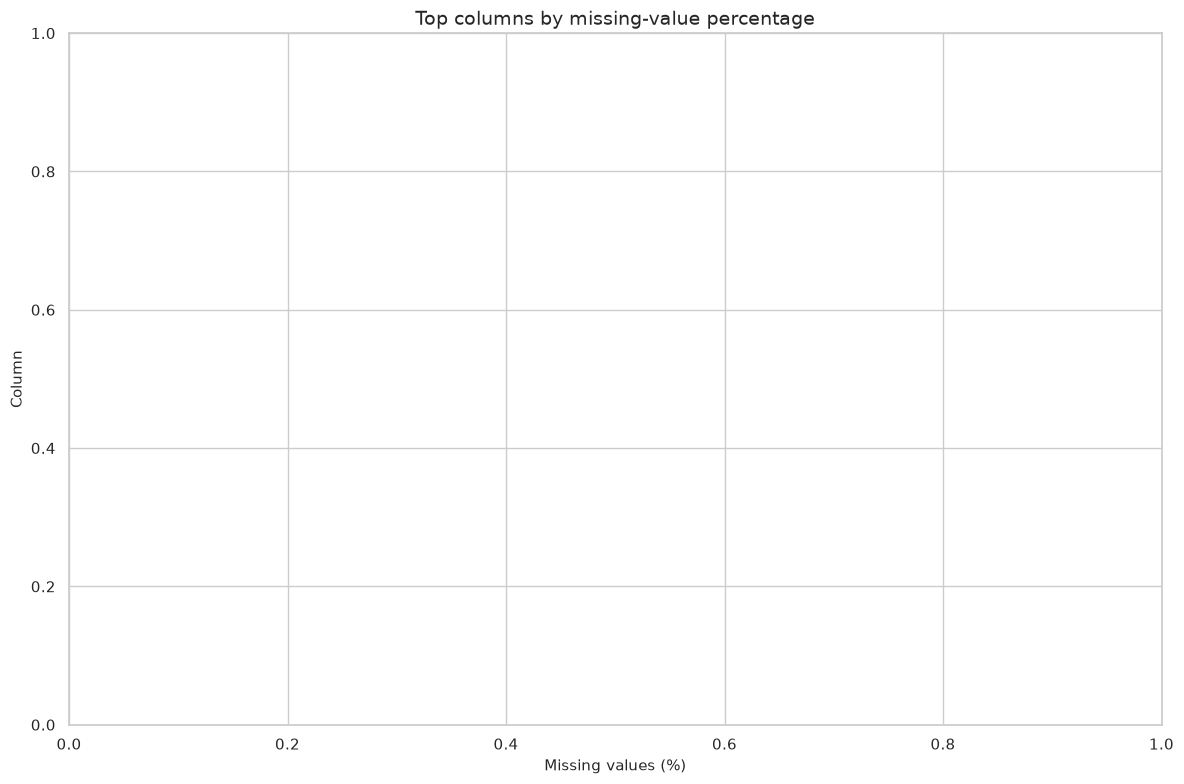

In [94]:
#missing value graph
# %%
missing_plot = missing[missing["missing_count"] > 0].head(30)

plt.figure(figsize=(12, 8))

sns.barplot(
    data=missing_plot.reset_index(),
    y="index",
    x="missing_pct",
    color="steelblue"
)

plt.title("Top columns by missing-value percentage")
plt.xlabel("Missing values (%)")
plt.ylabel("Column")
plt.tight_layout()

plt.show()

#normal that its empty, there are no missing values in this table


Found 1 numeric columns.


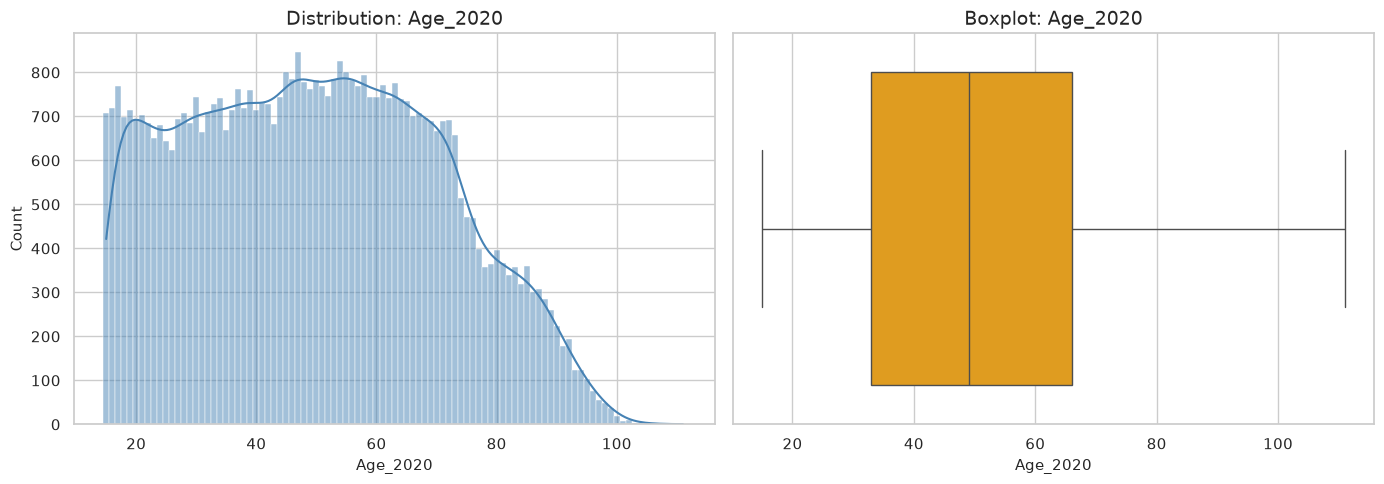

In [95]:
#Numeric distributions
# %%
numeric_cols = persons_learn.select_dtypes(
    include=np.number
).columns.tolist()

print(f"Found {len(numeric_cols)} numeric columns.")

for col in numeric_cols:
    fig, axes = plt.subplots(
        1, 2,
        figsize=(14, 5)
    )

    sns.histplot(
        persons_learn[col],
        discrete=True,
        kde=True,
        ax=axes[0],
        color="steelblue"
    )

    axes[0].set_title(f"Distribution: {col}")
    axes[0].set_xlabel(col)

    sns.boxplot(
        x=persons_learn[col],
        ax=axes[1],
        color="orange"
    )

    axes[1].set_title(f"Boxplot: {col}")
    axes[1].set_xlabel(col)

    plt.tight_layout()
    plt.show()


In [96]:
#Outliers
# %%
def outlier_summary(df):
    numeric_cols = df.select_dtypes(include=np.number).columns

    rows = []

    for col in numeric_cols:
        series = df[col].dropna()

        if len(series) == 0:
            continue

        q1 = series.quantile(0.25)
        q3 = series.quantile(0.75)
        iqr = q3 - q1

        lower = q1 - 1.5 * iqr
        upper = q3 + 1.5 * iqr

        outliers = ((series < lower) | (series > upper)).sum()

        rows.append({
            "column": col,
            "Q1": q1,
            "Q3": q3,
            "IQR": iqr,
            "lower_bound": lower,
            "upper_bound": upper,
            "outliers": outliers,
            "outlier_%": outliers / len(series) * 100,
        })

    return pd.DataFrame(rows).sort_values(
        "outlier_%",
        ascending=False
    )


outliers = outlier_summary(persons_learn)

display(
    outliers.style.format({
        "Q1": "{:,.2f}",
        "Q3": "{:,.2f}",
        "IQR": "{:,.2f}",
        "lower_bound": "{:,.2f}",
        "upper_bound": "{:,.2f}",
        "outlier_%": "{:.2f}%",
    })
)


,column,Q1,Q3,IQR,lower_bound,upper_bound,outliers,outlier_%
0,Age_2020,33.00,66.00,33.00,-16.50,115.50,0,0.00%


,n,pct_I
age_group,,
"(14, 17]",2196,35.2
"(17, 24]",4823,40.3
"(24, 34]",6942,60.4
"(34, 44]",7228,61.6
"(44, 54]",7880,56.2
"(54, 64]",7665,52.4
"(64, 74]",6749,57.2
"(74, 84]",3841,62.3
"(84, 94]",2354,61.2


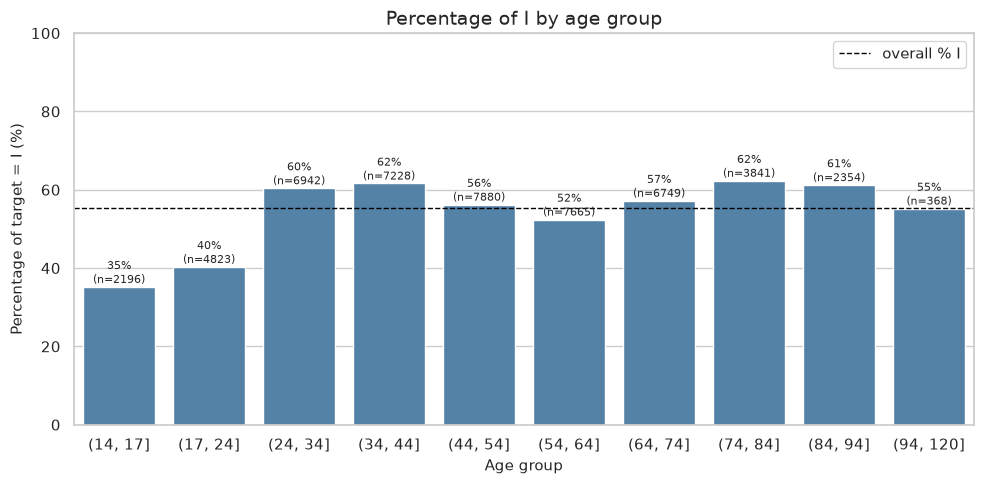

In [97]:
# Does the target depend on age? 
age_groups = pd.cut(
    persons_learn["Age_2020"],
    [14, 17, 24, 34, 44, 54, 64, 74, 84, 94, 120],
)
age_target = (
    persons_learn
    .assign(age_group=age_groups, is_I=persons_learn[TARGET_COL].eq("I"))
    .groupby("age_group", observed=True)
    .agg(n=("is_I", "size"), pct_I=("is_I", "mean"))
)
age_target["pct_I"] = (age_target["pct_I"] * 100).round(1)
display(age_target)

plt.figure(figsize=(10, 5))
ax = sns.barplot(x=age_target.index.astype(str), y=age_target["pct_I"], color="steelblue")
plt.axhline((persons_learn[TARGET_COL] == "I").mean() * 100, color="black", ls="--", lw=1, label="overall % I")
for i, (v, n) in enumerate(zip(age_target["pct_I"], age_target["n"])):
    ax.text(i, v + 1, f"{v:.0f}%\n(n={n})", ha="center", fontsize=8)
plt.ylim(0, 100)
plt.ylabel("Percentage of target = I (%)")
plt.xlabel("Age group")
plt.title("Percentage of I by age group")
plt.legend()
plt.tight_layout()
plt.savefig(FIGURES_DIR / "age_vs_target.png", dpi=150)
plt.show()


In [98]:
#categorical distributions
# %%
categorical_cols = persons_learn.select_dtypes(
    include=["object", "category", "bool"]
).columns.tolist()

print(f"Found {len(categorical_cols)} categorical columns.")


Found 9 categorical columns.


In [ ]:
#plot categorical values
# %%
def plot_categorical_distribution(df, col, top_n=50):
    counts = (
        df[col]
        .fillna("<MISSING>")
        .value_counts()
        .head(top_n)
        .sort_values()
    )

    # Booleans (IS_STUDENT) must become text labels, otherwise seaborn
    # treats True/False as numbers and draws a numeric axis
    labels = counts.index.astype(str)

    plt.figure(figsize=(10, max(4, 0.3 * len(counts))))

    sns.barplot(
        x=counts.values,
        y=labels,
        orient="h",
        color="steelblue"
    )

    if df[col].nunique(dropna=True) > top_n:
        plt.title(f"Top {top_n} values: {col}")
    else:
        plt.title(f"Distribution: {col}")
    plt.xlabel("Count")
    plt.ylabel(col)

    plt.tight_layout()
    plt.show()


# Automatically plot manageable categorical variables
# (threshold 50 so Job_42, 41 categories, is included; ids like Pkey/INSEE_CODE are not)
for col in categorical_cols:
    if persons_learn[col].nunique(dropna=True) <= 50:
        plot_categorical_distribution(
            persons_learn,
            col
        )

In [100]:
#high cardinality categorical values
# %%
high_cardinality = categorical_stats[
    categorical_stats["unique"] > 30
].copy()

display(
    high_cardinality[
        ["column", "unique", "missing_%", "top_value", "top_%"]
    ]
)


,column,unique,missing_%,top_value,top_%
0,Pkey,50046,0.0,1,0.001998
1,INSEE_CODE,13514,0.0,31555,0.753307
3,Job_42,41,0.0,csp_8_4,8.799904


In [101]:
#Analysis of variable target
# %%
if TARGET_COL in persons_learn.columns:

    print("Target distribution:")

    target_counts = persons_learn[TARGET_COL].value_counts(
        dropna=False
    )

    target_percent = (
        persons_learn[TARGET_COL]
        .value_counts(normalize=True, dropna=False)
        * 100
    )

    target_summary = pd.DataFrame({
        "count": target_counts,
        "percentage": target_percent
    })

    display(
        target_summary.style.format({
            "percentage": "{:.2f}%"
        })
    )

else:
    print(
        f"'{TARGET_COL}' is not present in the main dataset."
    )


Target distribution:


,count,percentage
target,,
I,27702,55.35%
T,22344,44.65%


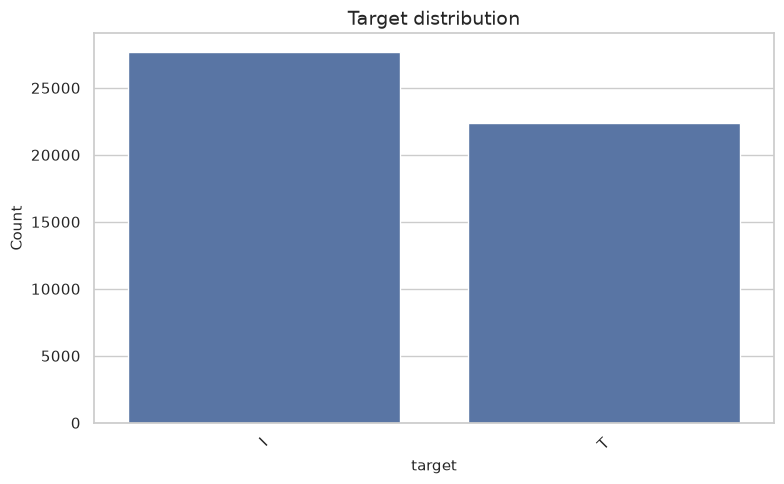

In [102]:
#Graph of variable target
# %%
if TARGET_COL in persons_learn.columns:

    plt.figure(figsize=(8, 5))

    sns.countplot(
        data=persons_learn,
        x=TARGET_COL,
        order=persons_learn[TARGET_COL].value_counts().index
    )

    plt.title("Target distribution")
    plt.xlabel(TARGET_COL)
    plt.ylabel("Count")
    plt.xticks(rotation=45)

    plt.tight_layout()
    plt.show()


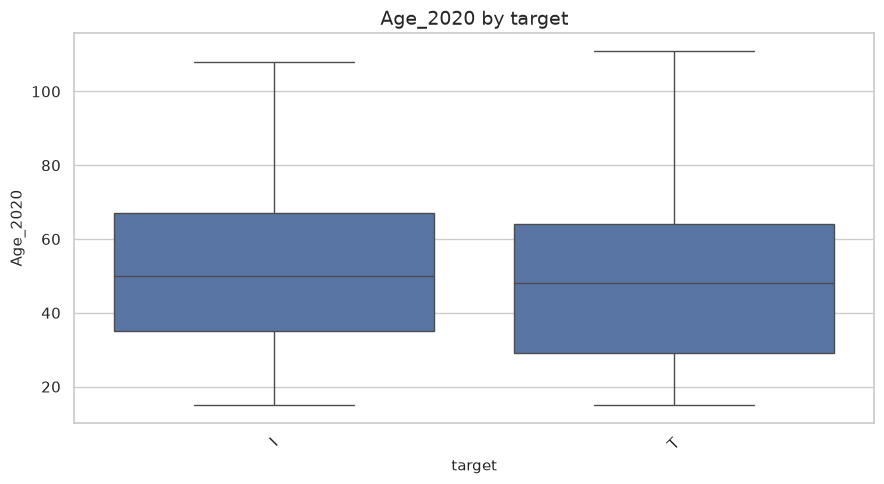

In [103]:
#Numeric variables vs target
# %%
if TARGET_COL in persons_learn.columns:

    numeric_cols = [
        col
        for col in persons_learn.select_dtypes(include=np.number).columns
        if col != TARGET_COL
    ]

    for col in numeric_cols:

        plt.figure(figsize=(9, 5))

        sns.boxplot(
            data=persons_learn,
            x=TARGET_COL,
            y=col
        )

        plt.title(f"{col} by target")
        plt.xticks(rotation=45)
        plt.tight_layout()

        plt.show()


In [ ]:
# Categorical variables vs target
# %%

if TARGET_COL in persons_learn.columns:

    # ---------------------------------------------------------
    # Target encoding for analysis only
    # ---------------------------------------------------------
    #
    # Original target:
    #   I = 1
    #   T = 0
    #
    # This does NOT modify persons_learn[TARGET_COL].
    #
    target_mapping = {
        "I": 1,
        "T": 0
    }

    target_numeric = persons_learn[TARGET_COL].map(
        target_mapping
    )

    # Check that all target values were successfully mapped
    unknown_targets = persons_learn.loc[
        target_numeric.isna(),
        TARGET_COL
    ].unique()

    if len(unknown_targets) > 0:
        print(
            "WARNING: Unknown target values found:",
            unknown_targets
        )

    # ---------------------------------------------------------
    # Find categorical variables
    # ---------------------------------------------------------

    categorical_cols = persons_learn.select_dtypes(
        include=["object", "category", "bool", "str"]
    ).columns.tolist()

    # Threshold 50 keeps Job_42 (41 categories) and still excludes
    # identifiers such as Pkey and INSEE_CODE (thousands of values)
    categorical_cols = [
        col
        for col in categorical_cols
        if col != TARGET_COL
        and persons_learn[col].nunique(dropna=True) <= 50
    ]

    print(
        f"Analyzing {len(categorical_cols)} categorical variables: {categorical_cols}"
    )

    overall_rate = target_numeric.mean() * 100

    # ---------------------------------------------------------
    # Analyze each categorical variable
    # ---------------------------------------------------------

    for col in categorical_cols:

        temp = pd.DataFrame({
            col: persons_learn[col],
            "_target_numeric": target_numeric
        })

        # Booleans (IS_STUDENT) are converted to text labels, otherwise
        # seaborn treats True/False as numbers and the bar plot breaks.
        # Missing values are treated as their own category.
        temp[col] = temp[col].astype("object").fillna("<MISSING>").astype(str)

        # Calculate:
        # - number of observations
        # - percentage I
        rates = (
            temp
            .groupby(col)["_target_numeric"]
            .agg(
                count="count",
                target_rate="mean"
            )
            .sort_values(
                "target_rate",
                ascending=False
            )
        )

        rates["target_rate"] *= 100

        # -----------------------------------------------------
        # Plot
        # -----------------------------------------------------

        plt.figure(figsize=(10, max(4, 0.35 * len(rates))))

        ax = sns.barplot(
            x=rates["target_rate"].to_numpy(),
            y=rates.index.to_numpy(),
            orient="h",
            color="steelblue"
        )

        # Reference line: share of I in the whole dataset
        ax.axvline(
            overall_rate,
            color="black",
            linestyle="--",
            linewidth=1,
            label=f"overall % I ({overall_rate:.1f}%)"
        )

        plt.title(
            f"Percentage of I by {col}"
        )

        plt.xlabel(
            "Percentage of target = I (%)"
        )

        plt.ylabel(col)

        # Add percentages and number of people to the bars
        for i, (value, n) in enumerate(
            zip(rates["target_rate"], rates["count"])
        ):
            ax.text(
                value + 0.5,
                i,
                f"{value:.1f}% (n={n:,})",
                va="center",
                fontsize=8
            )

        plt.xlim(0, 100)
        plt.legend(loc="lower right")

        plt.tight_layout()
        plt.show()

        # Show the statistics below each graph
        display(
            rates.style.format({
                "target_rate": "{:.2f}%"
            })
        )

In [105]:
#correlation matrix
# %%
numeric_df = persons_learn.select_dtypes(
    include=np.number
)

if numeric_df.shape[1] > 1:

    corr = numeric_df.corr()

    plt.figure(figsize=(14, 10))

    sns.heatmap(
        corr,
        cmap="coolwarm",
        center=0,
        annot=False
    )

    plt.title("Numeric feature correlation matrix")
    plt.tight_layout()

    plt.show()

    #Shows nothing because there is only one numeric variable, so there is no matrix


In [106]:
numeric_df = persons_learn.select_dtypes(include=np.number)

print("Numeric columns:", len(numeric_df.columns))
print(numeric_df.columns.tolist())

    #Shows nothing because there is only one numeric variable, so there is no matrix

Numeric columns: 1
['Age_2020']


In [107]:
#Get strongest correlations
# %%
if numeric_df.shape[1] > 1:

    corr_matrix = numeric_df.corr()

    pairs = (
        corr_matrix
        .where(
            np.triu(
                np.ones(corr_matrix.shape),
                k=1
            ).astype(bool)
        )
        .stack()
        .reset_index()
    )

    pairs.columns = [
        "feature_1",
        "feature_2",
        "correlation"
    ]

    pairs["abs_correlation"] = pairs["correlation"].abs()

    display(
        pairs.sort_values(
            "abs_correlation",
            ascending=False
        ).head(30)
    )
    #Shows nothing because there is only one numeric variable, so there is no matrix

In [108]:
#Feature engineering functions

#Here we start the adding variables to the dataset

# %%
def _flag(df, col):
    return df[col].notna()


def _add_job_description_levels(
    df,
    code_col,
    map_df,
    prefix
):
    """
    Map N3 job-description codes to broader N2 and N1 categories.
    """

    mapping = map_df.rename(
        columns={
            "N3": code_col,
            "N2": f"{prefix}_N2",
            "N1": f"{prefix}_N1",
        }
    )

    merged = df.merge(
        mapping,
        on=code_col,
        how="left"
    )

    return merged.drop(
        columns=[code_col]
    )


In [109]:
#Geography merge
# %%
def _merge_geography(persons):

    city_adm = load_city_adm()
    city_loc = load_city_loc()
    city_pop = load_city_pop()
    departments = load_departments()
    regions = load_regions()

    geo = (
        city_adm
        .merge(
            city_loc,
            on="INSEE_CODE",
            how="left"
        )
        .merge(
            city_pop,
            on="INSEE_CODE",
            how="left"
        )
        .merge(
            departments,
            on="dep",
            how="left"
        )
        .merge(
            regions,
            on="Reg",
            how="left"
        )
    )

    out = persons.merge(
        geo,
        on="INSEE_CODE",
        how="left"
    )

    if {"X", "Y"}.issubset(out.columns):

        out["distance_to_paris_km"] = (
            np.sqrt(
                (out["X"] - PARIS_LAMBERT93_X) ** 2
                +
                (out["Y"] - PARIS_LAMBERT93_Y) ** 2
            )
            / 1000.0
        )

    if "INHABITANTS" in out.columns:

        out["log_inhabitants"] = np.log1p(
            out["INHABITANTS"]
        )

    return out


In [110]:
#club merge
# %%
def _merge_club(persons, split):

    club = load_club(split)

    code_club = load_code_club().rename(
        columns={
            "Code": "club",
            "Categorie": "club_category",
            "Nom fédération": "club_federation",
            "Nom catégorie": "club_category_name",
        }
    )

    club = club.merge(
        code_club,
        on="club",
        how="left"
    )

    columns_to_keep = [
        col
        for col in [
            "Pkey",
            "club_category",
            "club_federation"
        ]
        if col in club.columns
    ]

    out = persons.merge(
        club[columns_to_keep],
        on="Pkey",
        how="left"
    )

    if "club_category" in out.columns:
        out["has_club"] = _flag(
            out,
            "club_category"
        )

    return out


In [111]:
#consistency checks
# %%
def _consistency_checks(df, split):

    print(f"\n[{split}] consistency checks")

    if {
        "has_job_detail",
        "has_emp_contract"
    }.issubset(df.columns):

        mismatch = (
            df["has_job_detail"]
            &
            ~df["has_emp_contract"]
        )

        print(
            "Job detail without EMP_CONTRACT:",
            mismatch.sum()
        )

    if {
        "Act",
        "has_emp_contract"
    }.issubset(df.columns):

        employed = (
            df["Act"] == "tact1-1"
        )

        mismatch = (
            employed
            &
            ~df["has_emp_contract"]
        )

        print(
            "Act=employed without EMP_CONTRACT:",
            mismatch.sum()
        )

    if {
        "Act",
        "has_retired_former"
    }.issubset(df.columns):

        retired = (
            df["Act"] == "tact2-1"
        )

        mismatch = (
            retired
            &
            ~df["has_retired_former"]
        )

        print(
            "Act=retired without retired_former:",
            mismatch.sum()
        )


In [112]:
#Build dataset with merge diagnostics
# %%
def build_dataset(split, return_diagnostics=False):

    assert split in ("learn", "test")

    diagnostics = []

    def record(stage, dataframe):
        diagnostics.append({
            "stage": stage,
            "rows": len(dataframe),
            "columns": len(dataframe.columns),
            "missing_cells": dataframe.isna().sum().sum(),
        })

    # Main table
    df = load_persons(split)
    record("persons", df)

    # Employment
    emp = load_emp_contract(split)

    df = df.merge(
        emp,
        on="Pkey",
        how="left"
    )

    if "EMP_CONTRACT" in df.columns:
        df["has_emp_contract"] = _flag(
            df,
            "EMP_CONTRACT"
        )

    record("after employment merge", df)

    # Current job
    job = load_job(split)
    job_map = load_job_description_map()

    if "Job_description" in job.columns:

        job = _add_job_description_levels(
            job,
            "Job_description",
            job_map,
            prefix="Job_description"
        )

    df = df.merge(
        job,
        on="Pkey",
        how="left"
    )

    if "Eco_sect" in df.columns:
        df["has_job_detail"] = _flag(
            df,
            "Eco_sect"
        )

    record("after current job merge", df)

    # Retired former
    retired_former = load_retired_former(split)

    df = df.merge(
        retired_former,
        on="Pkey",
        how="left"
    )

    if "Former_job_42" in df.columns:
        df["has_retired_former"] = _flag(
            df,
            "Former_job_42"
        )

    record("after retired former merge", df)

    # Retired detailed jobs
    retired_jobs = load_retired_jobs(split)

    if "Job_description" in retired_jobs.columns:

        retired_jobs = _add_job_description_levels(
            retired_jobs,
            "Job_description",
            job_map,
            prefix="Former_job_description"
        )

    df = df.merge(
        retired_jobs,
        on="Pkey",
        how="left",
        suffixes=("", "_former_job")
    )

    if "Eco_sect_former_job" in df.columns:
        df["has_retired_job_detail"] = _flag(
            df,
            "Eco_sect_former_job"
        )

    record("after retired jobs merge", df)

    # Pension
    pension = load_retired_pension(split)

    df = df.merge(
        pension,
        on="Pkey",
        how="left"
    )

    if "retirement_pay" in df.columns:
        df["has_pension"] = _flag(
            df,
            "retirement_pay"
        )

    record("after pension merge", df)

    # Club
    df = _merge_club(
        df,
        split
    )

    record("after club merge", df)

    # Geography
    df = _merge_geography(df)

    record("after geography merge", df)

    # Diagnostics
    _consistency_checks(
        df,
        split
    )

    diagnostics_df = pd.DataFrame(
        diagnostics
    )

    if return_diagnostics:
        return df, diagnostics_df

    return df


In [113]:
#Build learn and test dfs
# %%
learn_features, learn_merge_diagnostics = build_dataset(
    "learn",
    return_diagnostics=True
)

test_features, test_merge_diagnostics = build_dataset(
    "test",
    return_diagnostics=True
)

print("Learn:", learn_features.shape)
print("Test:", test_features.shape)



[learn] consistency checks
Job detail without EMP_CONTRACT: 0
Act=employed without EMP_CONTRACT: 0
Act=retired without retired_former: 275

[test] consistency checks
Job detail without EMP_CONTRACT: 0
Act=employed without EMP_CONTRACT: 0
Act=retired without retired_former: 245
Learn: (50046, 58)
Test: (50045, 57)


,stage,rows,columns,missing_cells
0,persons,50046,10,0
1,after employment merge,50046,12,25950
2,after current job merge,50046,24,366378
3,after retired former merge,50046,28,476775
4,after retired jobs merge,50046,40,905765
5,after pension merge,50046,42,944567
6,after club merge,50046,45,1031951
7,after geography merge,50046,58,1031951


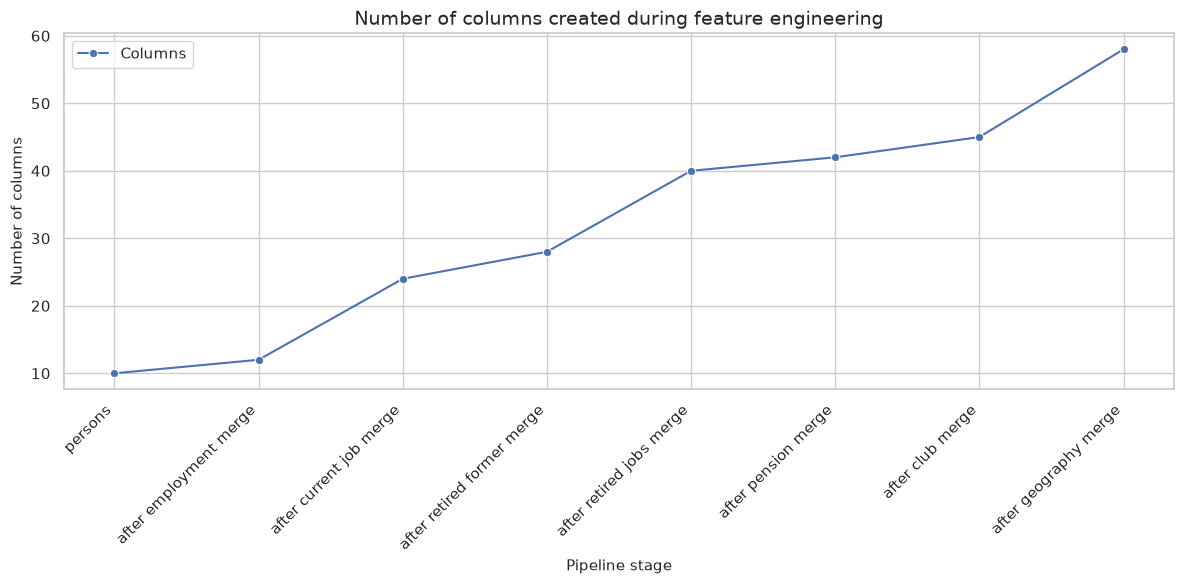

In [114]:
#Visualize merge process
# %%
display(learn_merge_diagnostics)

plt.figure(figsize=(12, 6))

sns.lineplot(
    data=learn_merge_diagnostics,
    x="stage",
    y="columns",
    marker="o",
    label="Columns"
)

plt.xticks(rotation=45, ha="right")
plt.title("Number of columns created during feature engineering")
plt.ylabel("Number of columns")
plt.xlabel("Pipeline stage")

plt.tight_layout()
plt.show()


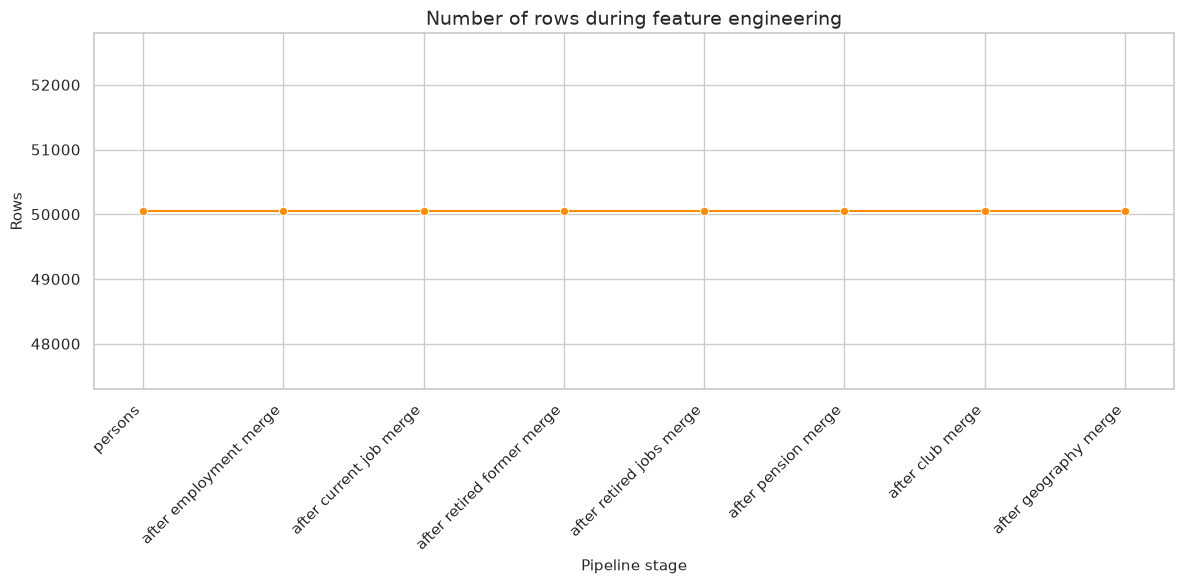

In [115]:
# %%
plt.figure(figsize=(12, 6))

sns.lineplot(
    data=learn_merge_diagnostics,
    x="stage",
    y="rows",
    marker="o",
    color="darkorange"
)

plt.xticks(rotation=45, ha="right")
plt.title("Number of rows during feature engineering")
plt.ylabel("Rows")
plt.xlabel("Pipeline stage")

plt.tight_layout()
plt.show()


In [116]:
#Final feature inventory of the df
# %%
learn_feature_info = inspect_dataframe(
    learn_features,
    "Final engineered learn dataset"
)


## Final engineered learn dataset

Shape: (50046, 58)
Duplicate rows: 0


,dtype,non_null,missing,missing_%,unique,memory_MB
club_federation,str,6354,43692,87.303681,96,0.647409
club_category,float64,6354,43692,87.303681,5,0.381947
COMPANY_CATEGORY_former_job,str,10482,39564,79.055269,9,0.427898
Employee_count_former_job,str,10550,39496,78.919394,7,0.428158
former_dep,str,10886,39160,78.248012,96,0.408676
Job_dep_former_job,str,10903,39143,78.214043,96,0.408709
working_hours_former_job,float64,11231,38815,77.558646,2084,0.381947
type_of_contract_former_job,str,11244,38802,77.532670,5,0.420082
retirement_pay,float64,11244,38802,77.532670,8051,0.381947
Former_job_description_N1,str,11244,38802,77.532670,4,0.441528


In [117]:
#Newly created features
# %%
original_columns = set(persons_learn.columns)
engineered_columns = [
    col
    for col in learn_features.columns
    if col not in original_columns
]

print(
    f"Original columns: {len(original_columns)}"
)

print(
    f"Final columns: {len(learn_features.columns)}"
)

print(
    f"New columns: {len(engineered_columns)}"
)

display(
    pd.DataFrame({
        "engineered_feature": engineered_columns
    })
)


Original columns: 10
Final columns: 58
New columns: 48


,engineered_feature
0,EMP_CONTRACT
1,has_emp_contract
2,Eco_sect
3,Employee_count
4,Job_dep
5,PAY
6,COMPANY_CATEGORY
7,type_of_contract
8,labor_force_status
9,working_hours


Merged learn dataframe: 50,046 rows x 58 columns
Missing cells: 1,031,951 of 2,902,668 (35.6%)
Columns with at least one missing value: 29 / 58
Columns with no missing value: 29


,missing,missing_pct,source
club_federation,43692,87.30%,club
club_category,43692,87.30%,club
COMPANY_CATEGORY_former_job,39564,79.06%,retired_jobs
Employee_count_former_job,39496,78.92%,retired_jobs
former_dep,39160,78.25%,retired_jobs
Job_dep_former_job,39143,78.21%,retired_jobs
working_hours_former_job,38815,77.56%,retired_jobs
Eco_sect_former_job,38802,77.53%,retired_jobs
retirement_pay,38802,77.53%,retired_pension
Former_job_description_N1,38802,77.53%,retired_jobs


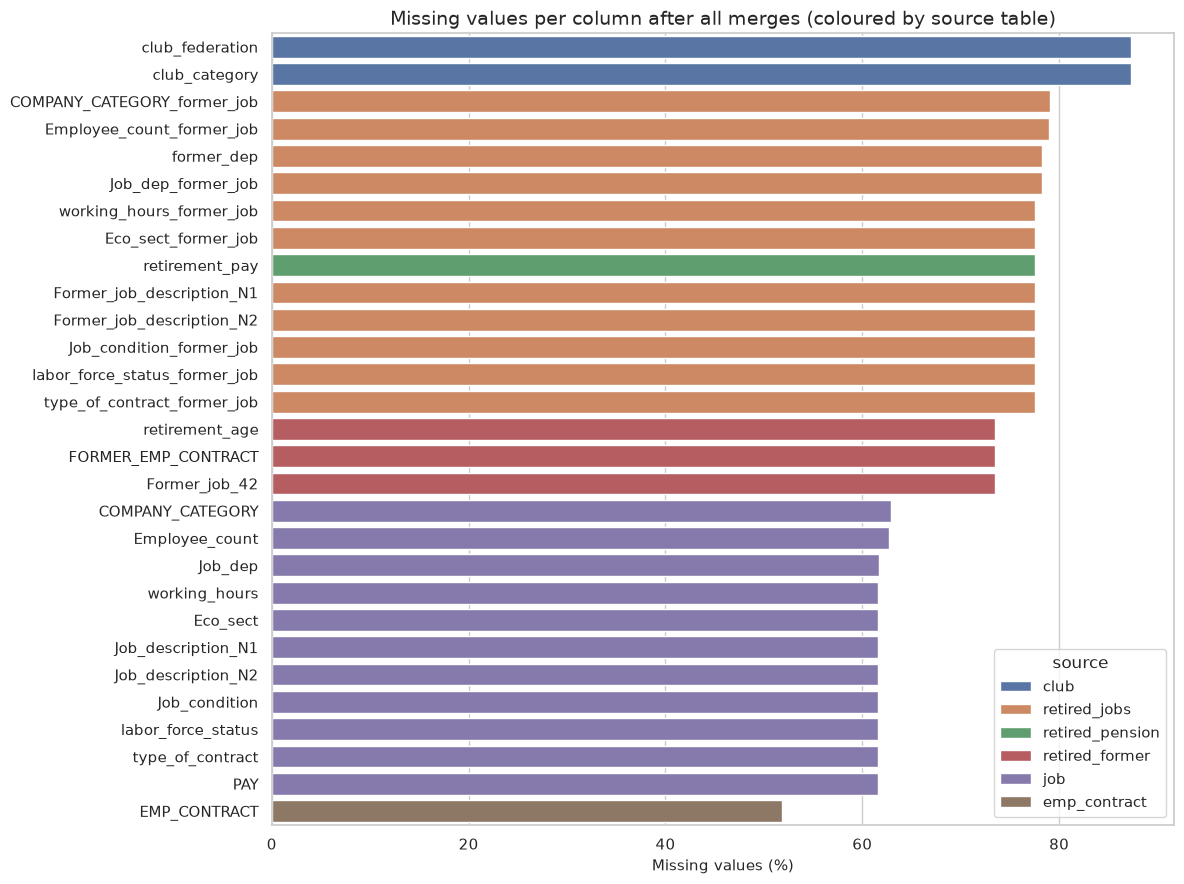

In [118]:
# Overall missingness of the merged learn dataframe, grouped by source table
source_tables = {
    "emp_contract": "emp_contract_learn",
    "job": "job_learn",
    "retired_former": "retired_former_learn",
    "retired_jobs": "retired_jobs_learn",
    "retired_pension": "retired_pension_learn",
    "club": "club_learn",
}

in_table = pd.DataFrame({
    name: learn_features[ID_COL].isin(raw[raw_name][ID_COL])
    for name, raw_name in source_tables.items()
})

# Which merged column comes from which table
column_source = {}
column_source.update({c: "emp_contract" for c in ["EMP_CONTRACT"]})
column_source.update({c: "job" for c in [
    "Eco_sect", "Employee_count", "Job_dep", "PAY", "COMPANY_CATEGORY", "type_of_contract",
    "labor_force_status", "working_hours", "Job_condition", "Job_description_N2", "Job_description_N1"]})
column_source.update({c: "retired_former" for c in [
    "Former_job_42", "FORMER_EMP_CONTRACT", "retirement_age"]})
column_source.update({c: "retired_jobs" for c in [
    "Eco_sect_former_job", "former_dep", "Job_dep_former_job", "type_of_contract_former_job",
    "labor_force_status_former_job", "Job_condition_former_job", "COMPANY_CATEGORY_former_job",
    "working_hours_former_job", "Employee_count_former_job", "Former_job_description_N2",
    "Former_job_description_N1"]})
column_source.update({c: "retired_pension" for c in ["retirement_pay"]})
column_source.update({c: "club" for c in ["club_category", "club_federation"]})

total_cells = learn_features.shape[0] * learn_features.shape[1]
total_missing = learn_features.isna().sum().sum()
print(f"Merged learn dataframe: {learn_features.shape[0]:,} rows x {learn_features.shape[1]} columns")
print(f"Missing cells: {total_missing:,} of {total_cells:,} ({total_missing / total_cells:.1%})")
print(f"Columns with at least one missing value: {(learn_features.isna().sum() > 0).sum()} / {learn_features.shape[1]}")
print(f"Columns with no missing value: {(learn_features.isna().sum() == 0).sum()}")

missing_after_merge = (
    learn_features.isna().sum().to_frame("missing")
    .assign(
        missing_pct=lambda d: d["missing"] / len(learn_features) * 100,
        source=lambda d: d.index.map(column_source).fillna("persons / geography / flags"),
    )
    .query("missing > 0")
    .sort_values("missing_pct", ascending=False)
)
display(missing_after_merge.style.format({"missing_pct": "{:.2f}%"}))

plt.figure(figsize=(12, 9))
sns.barplot(
    data=missing_after_merge.reset_index(names="column"),
    y="column", x="missing_pct", hue="source", dodge=False,
)
plt.title("Missing values per column after all merges (coloured by source table)")
plt.xlabel("Missing values (%)")
plt.ylabel("")
plt.tight_layout()
plt.savefig(FIGURES_DIR / "missing_after_merge.png", dpi=150)
plt.show()


In [119]:
# Structural vs real missingness
# For every column coming from an auxiliary table:
#  - structural_missing = person is NOT in that table (value does not exist)
#  - real_missing       = person IS in that table but the field is empty in the raw file
rows = []
for col, src in column_source.items():
    member = in_table[src]
    na = learn_features[col].isna()
    rows.append({
        "column": col,
        "source": src,
        "people_in_table": member.sum(),
        "structural_missing": (na & ~member).sum(),
        "real_missing": (na & member).sum(),
        "real_missing_%_of_members": (na & member).sum() / member.sum() * 100,
    })

structural_vs_real = pd.DataFrame(rows).set_index("column")
display(
    structural_vs_real.sort_values("real_missing", ascending=False)
    .style.format({"real_missing_%_of_members": "{:.2f}%"})
)

total_struct = structural_vs_real["structural_missing"].sum()
total_real = structural_vs_real["real_missing"].sum()
print(f"Structural missing cells: {total_struct:,} ({total_struct / (total_struct + total_real):.1%})")
print(f"Real missing cells:       {total_real:,} ({total_real / (total_struct + total_real):.1%})")


,source,people_in_table,structural_missing,real_missing,real_missing_%_of_members
column,,,,,
COMPANY_CATEGORY_former_job,retired_jobs,11244,38802,762,6.78%
Employee_count_former_job,retired_jobs,11244,38802,694,6.17%
COMPANY_CATEGORY,job,19211,30835,659,3.43%
Employee_count,job,19211,30835,543,2.83%
former_dep,retired_jobs,11244,38802,358,3.18%
Job_dep_former_job,retired_jobs,11244,38802,341,3.03%
Job_dep,job,19211,30835,29,0.15%
working_hours_former_job,retired_jobs,11244,38802,13,0.12%
working_hours,job,19211,30835,11,0.06%


Structural missing cells: 1,028,540 (99.7%)
Real missing cells:       3,411 (0.3%)


In [120]:
#  Why is a person in a table or not? -> it is explained by the activity status (Act)
# Each row: activity status. Each column: % of people of that status present in each auxiliary table.
membership_by_act = (
    in_table.assign(Act=learn_features["Act"])
    .groupby("Act")
    .mean()
    .mul(100)
    .round(1)
)
membership_by_act.insert(0, "n_people", learn_features["Act"].value_counts().sort_index())
display(membership_by_act)

# Profiles of table membership (which combination of tables each person has data in)
profiles = (
    in_table.apply(lambda r: " + ".join(c for c in in_table.columns if r[c]) or "(only base table)", axis=1)
    .value_counts()
    .to_frame("n_people")
)
profiles["%"] = (profiles["n_people"] / len(learn_features) * 100).round(2)
display(profiles)


,n_people,emp_contract,job,retired_former,retired_jobs,retired_pension,club
Act,,,,,,,
tact1-1,24096,100.0,79.7,0.0,0.0,0.0,12.7
tact1-2,3675,0.0,0.0,0.0,0.0,0.0,13.7
tact2-1,13522,0.0,0.0,98.0,83.2,83.2,8.0
tact2-2,5230,0.0,0.0,0.0,0.0,0.0,24.8
tact2-4,1408,0.0,0.0,0.0,0.0,0.0,8.0
tact2-5,2115,0.0,0.0,0.0,0.0,0.0,14.0


,n_people,%
emp_contract + job,16811,33.59
(only base table),10469,20.92
retired_former + retired_jobs + retired_pension,10341,20.66
emp_contract,4226,8.44
emp_contract + job + club,2400,4.80
club,2234,4.46
retired_former,1845,3.69
retired_former + retired_jobs + retired_pension + club,903,1.80
emp_contract + club,659,1.32
retired_former + club,158,0.32


In [121]:
# Inconsistencies detected by _consistency_checks (Act = retired but no retired_former row)
retired_no_former = (learn_features["Act"] == "tact2-1") & ~in_table["retired_former"]
print("Retired (Act=tact2-1) without a retired_former row:", retired_no_former.sum())
print("Of those, present in retired_jobs:", (retired_no_former & in_table["retired_jobs"]).sum(),
      "| present in retired_pension:", (retired_no_former & in_table["retired_pension"]).sum())
print("% I among them:", round(is_I[retired_no_former].mean() * 100, 1),
      "vs % I among all retired:", round(is_I[learn_features["Act"] == "tact2-1"].mean() * 100, 1))

# Same picture in test, to make sure the missingness structure is identical (it is what the model will see)
test_struct = pd.DataFrame({
    "learn_%_in_table": in_table.mean().mul(100).round(2),
    "test_%_in_table": pd.Series({
        name: test_features[ID_COL].isin(raw[raw_name.replace("learn", "test")][ID_COL]).mean() * 100
        for name, raw_name in source_tables.items()
    }).round(2),
})
display(test_struct)


Retired (Act=tact2-1) without a retired_former row: 275
Of those, present in retired_jobs: 0 | present in retired_pension: 0
% I among them: 57.5 vs % I among all retired: 59.9


,learn_%_in_table,test_%_in_table
emp_contract,48.15,48.15
job,38.39,38.40
retired_former,26.47,26.72
retired_jobs,22.47,22.56
retired_pension,22.47,22.56
club,12.70,12.85


In [122]:
#Analyze the "has_" features
# %%
has_columns = [
    col
    for col in learn_features.columns
    if col.startswith("has_")
]

has_summary = pd.DataFrame({
    "feature": has_columns,
    "count_true": [
        learn_features[col].sum()
        for col in has_columns
    ],
    "percentage_true": [
        learn_features[col].mean() * 100
        for col in has_columns
    ]
}).sort_values(
    "percentage_true",
    ascending=False
)

display(
    has_summary.style.format({
        "percentage_true": "{:.2f}%"
    })
)


,feature,count_true,percentage_true
0,has_emp_contract,24096,48.15%
1,has_job_detail,19210,38.38%
2,has_retired_former,13247,26.47%
3,has_retired_job_detail,11244,22.47%
4,has_pension,11244,22.47%
5,has_club,6354,12.70%


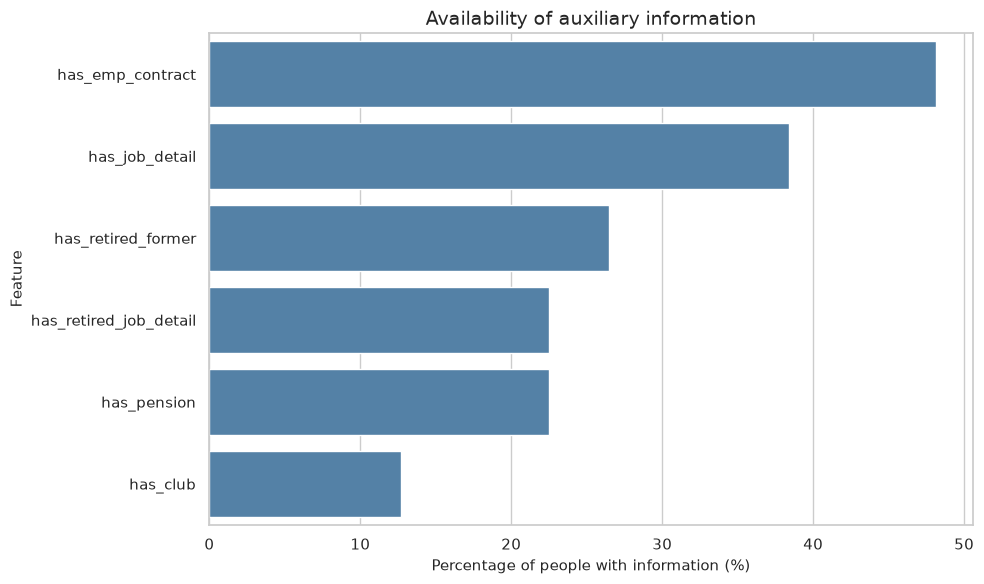

In [123]:
#plot feature availability
# %%
plt.figure(figsize=(10, 6))

sns.barplot(
    data=has_summary,
    x="percentage_true",
    y="feature",
    color="steelblue"
)

plt.title("Availability of auxiliary information")
plt.xlabel("Percentage of people with information (%)")
plt.ylabel("Feature")

plt.tight_layout()
plt.show()


In [124]:
#Geographic feature analysis
# %%
geo_features = [
    col
    for col in [
        "INHABITANTS",
        "log_inhabitants",
        "X",
        "Y",
        "distance_to_paris_km"
    ]
    if col in learn_features.columns
]

display(
    numeric_statistics(
        learn_features[geo_features]
    )
)


,count,mean,std,min,25%,50%,75%,max,missing,missing_%,unique,skewness
INHABITANTS,50046.0,4.217942e+04,75478.017595,1.500000e+01,2.308000e+03,1.001700e+04,4.562500e+04,4.985960e+05,0,0.0,5675,3.134109
log_inhabitants,50046.0,9.200226e+00,1.914300,2.772589e+00,7.744570e+00,9.212139e+00,1.072823e+01,1.311955e+01,0,0.0,5675,-0.115054
X,50046.0,6.742466e+05,207183.247885,1.117439e+05,5.534540e+05,6.588516e+05,8.419640e+05,1.237369e+06,0,0.0,13514,-0.133345
Y,50046.0,6.664809e+06,250684.011947,6.057380e+06,6.457329e+06,6.737336e+06,6.863711e+06,7.108708e+06,0,0.0,13514,-0.389108
distance_to_paris_km,50046.0,3.144378e+02,215.049740,2.757672e-01,1.299395e+02,3.220954e+02,4.750949e+02,9.832943e+02,0,0.0,13514,0.177809


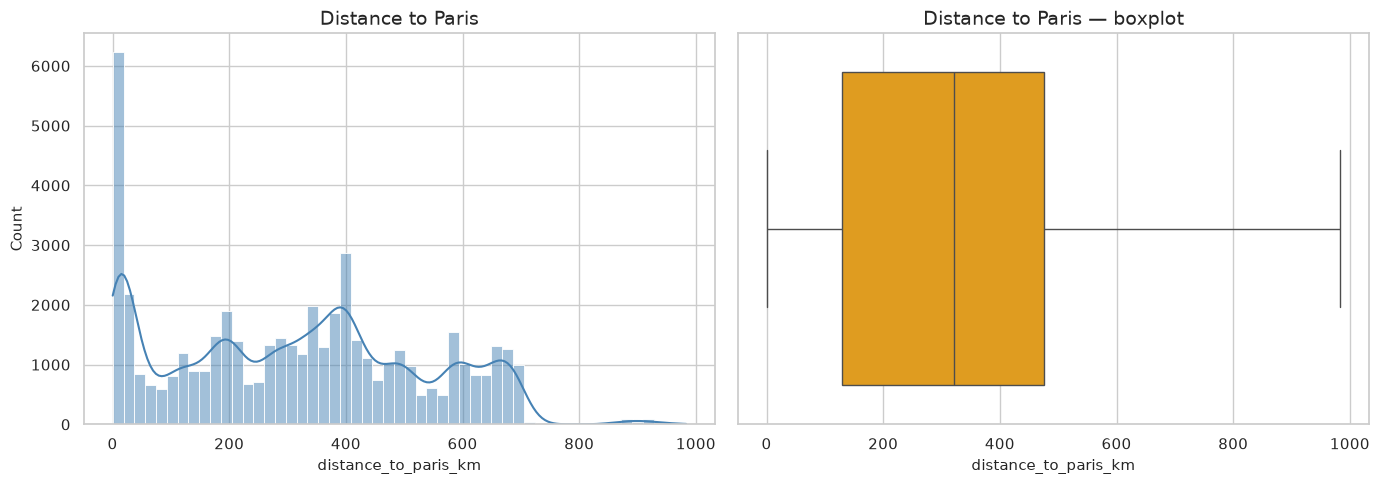

In [125]:
#distance to paris
# %%
if "distance_to_paris_km" in learn_features.columns:

    fig, axes = plt.subplots(
        1,
        2,
        figsize=(14, 5)
    )

    sns.histplot(
        learn_features["distance_to_paris_km"],
        kde=True,
        ax=axes[0],
        color="steelblue"
    )

    axes[0].set_title(
        "Distance to Paris"
    )

    sns.boxplot(
        x=learn_features["distance_to_paris_km"],
        ax=axes[1],
        color="orange"
    )

    axes[1].set_title(
        "Distance to Paris — boxplot"
    )

    plt.tight_layout()
    plt.show()


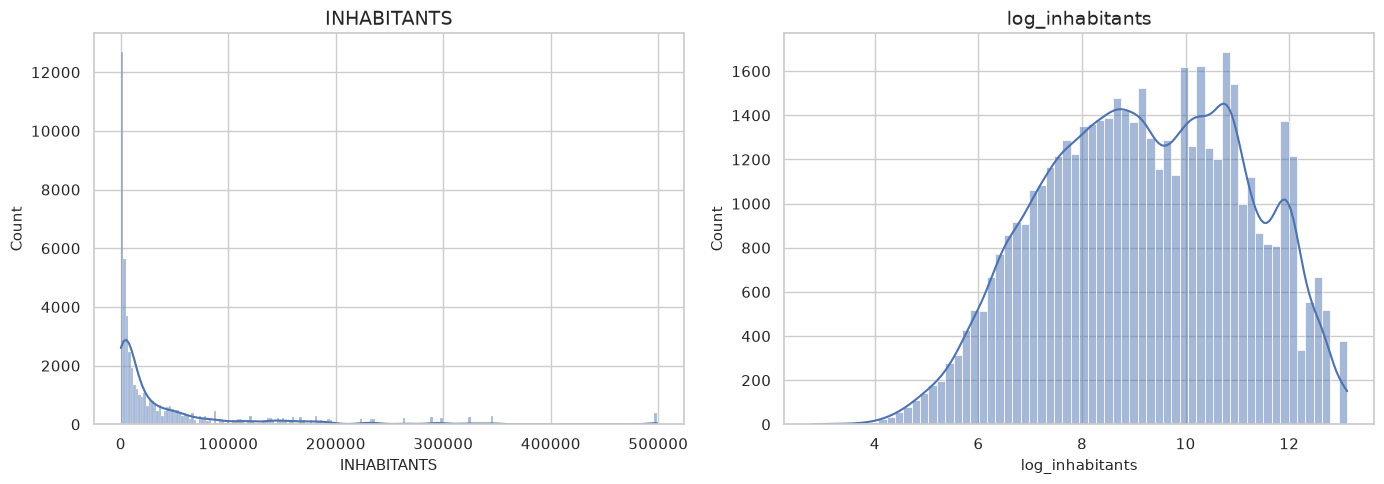

In [126]:
#population analysis
# %%
population_cols = [
    col
    for col in [
        "INHABITANTS",
        "log_inhabitants"
    ]
    if col in learn_features.columns
]

if population_cols:

    fig, axes = plt.subplots(
        1,
        len(population_cols),
        figsize=(14, 5)
    )

    if len(population_cols) == 1:
        axes = [axes]

    for ax, col in zip(
        axes,
        population_cols
    ):

        sns.histplot(
            learn_features[col],
            kde=True,
            ax=ax
        )

        ax.set_title(col)

    plt.tight_layout()
    plt.show()


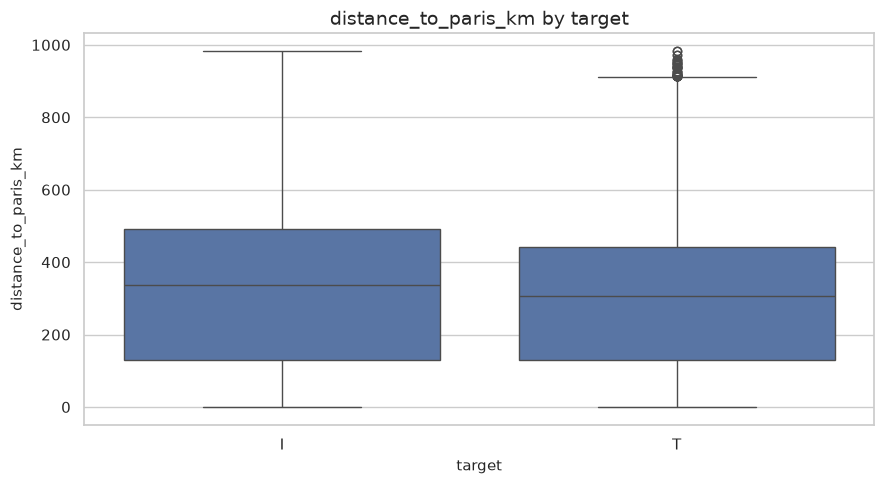

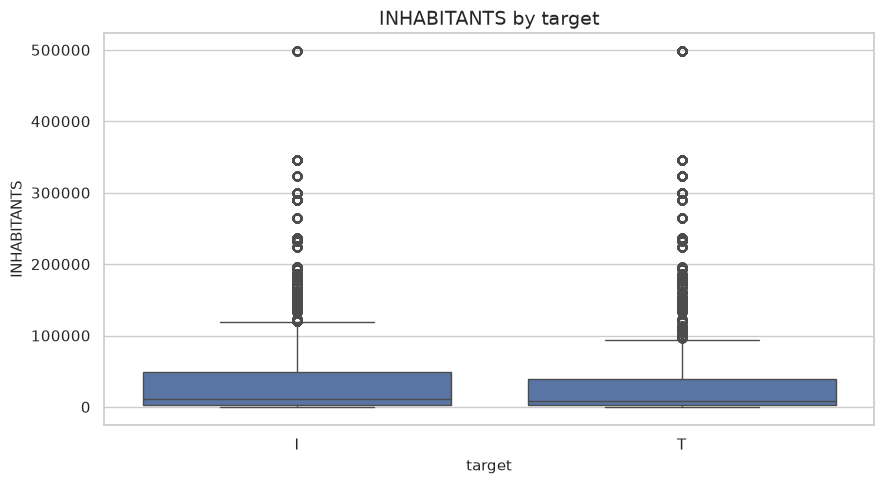

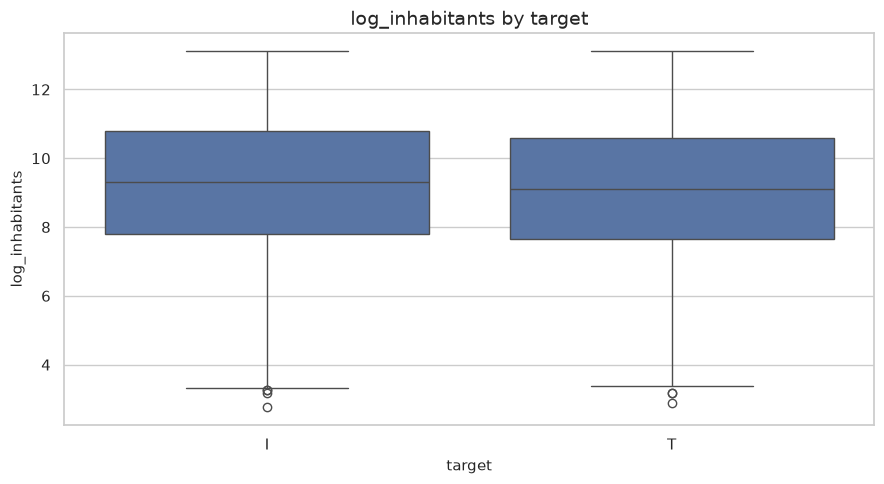

In [127]:
#Geography vs target
# %%
if TARGET_COL in learn_features.columns:

    for col in [
        "distance_to_paris_km",
        "INHABITANTS",
        "log_inhabitants"
    ]:

        if col not in learn_features.columns:
            continue

        plt.figure(figsize=(9, 5))

        sns.boxplot(
            data=learn_features,
            x=TARGET_COL,
            y=col
        )

        plt.title(
            f"{col} by target"
        )

        plt.tight_layout()
        plt.show()


In [128]:
#Job description analysis
# %%
job_columns = [
    col
    for col in learn_features.columns
    if (
        "Job_description" in col
        or "job_description" in col
    )
]

print("Job-related columns:")
for col in job_columns:
    print(" -", col)


Job-related columns:
 - Job_description_N2
 - Job_description_N1
 - Former_job_description_N2
 - Former_job_description_N1


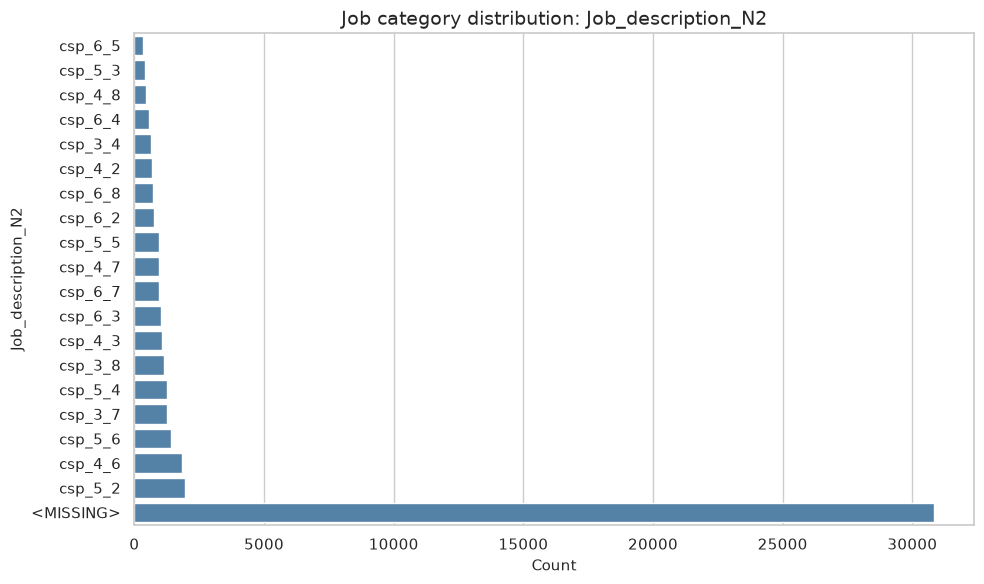

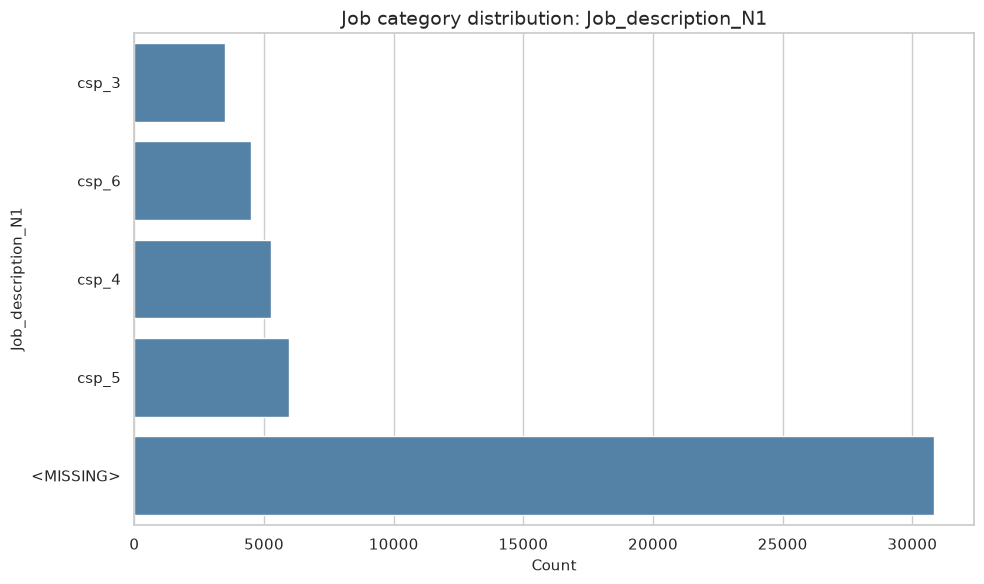

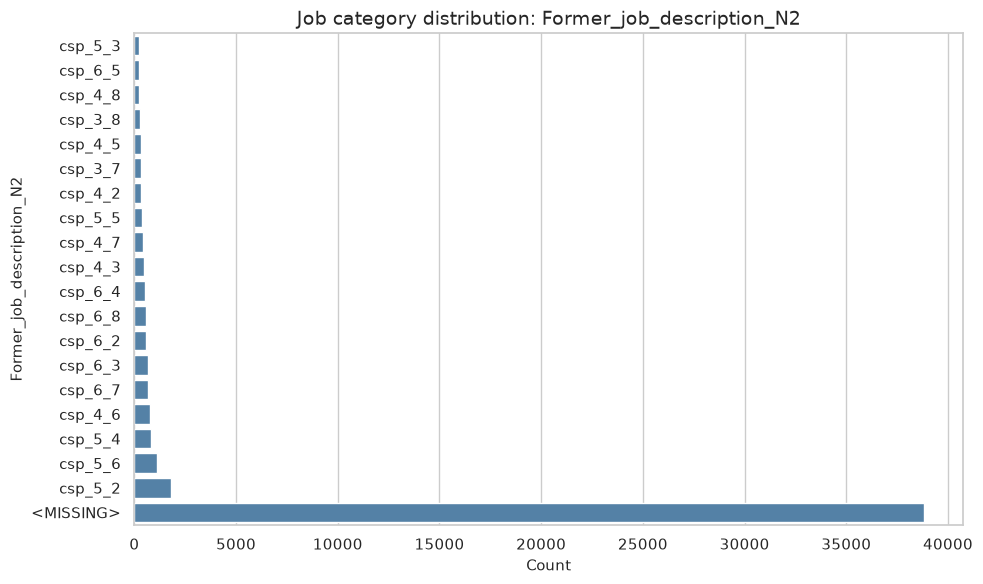

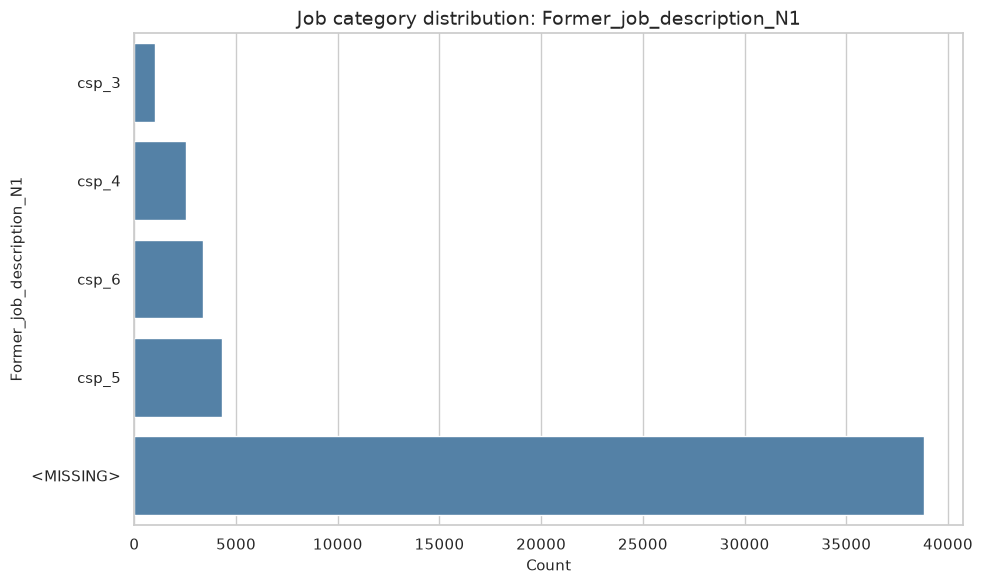

In [129]:
#Job category distributions
# %%
for col in job_columns:

    if learn_features[col].nunique(dropna=True) <= 30:

        counts = (
            learn_features[col]
            .fillna("<MISSING>")
            .value_counts()
            .head(20)
            .sort_values()
        )

        plt.figure(figsize=(10, 6))

        sns.barplot(
            x=counts.values,
            y=counts.index,
            color="steelblue"
        )

        plt.title(
            f"Job category distribution: {col}"
        )

        plt.xlabel("Count")
        plt.ylabel(col)

        plt.tight_layout()
        plt.show()


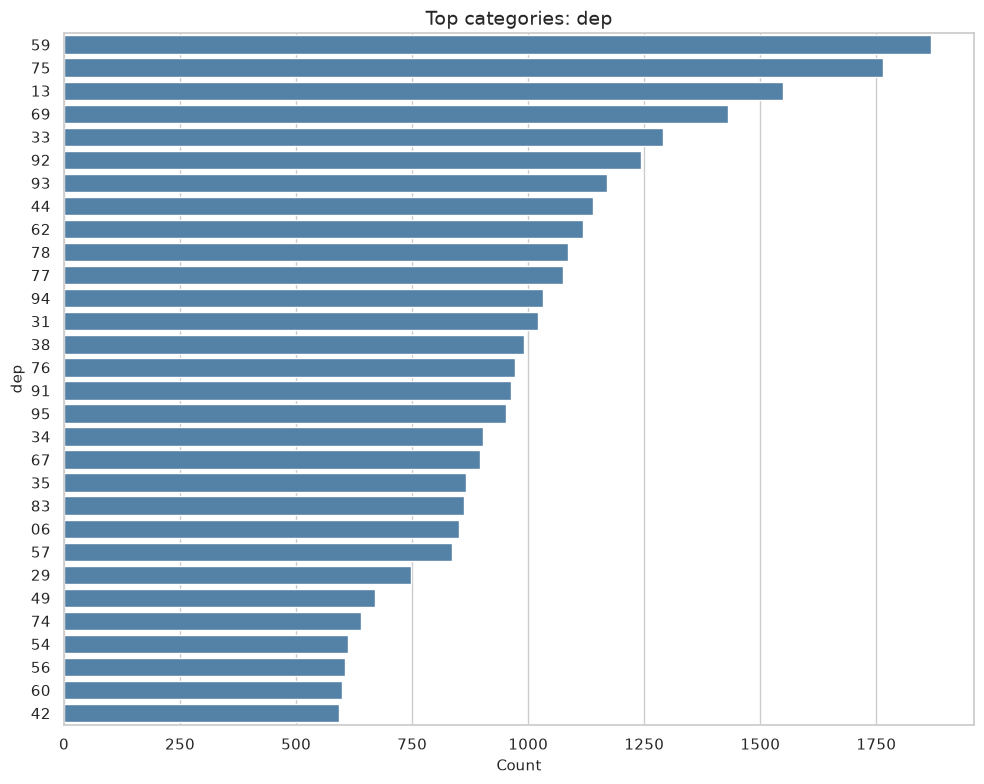

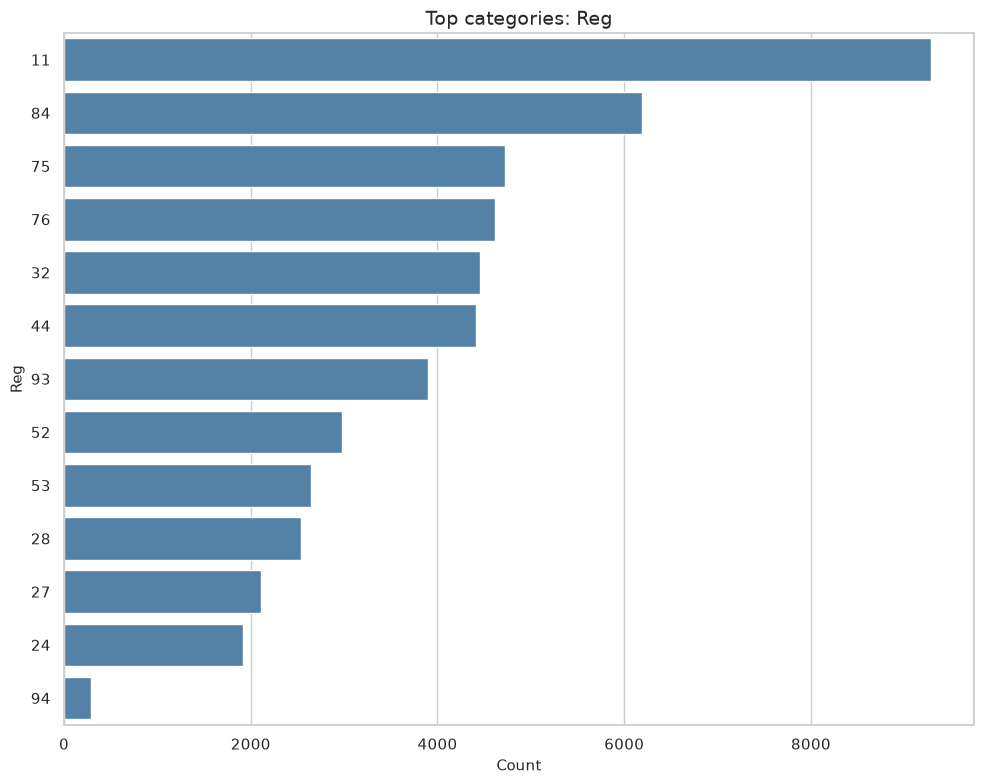

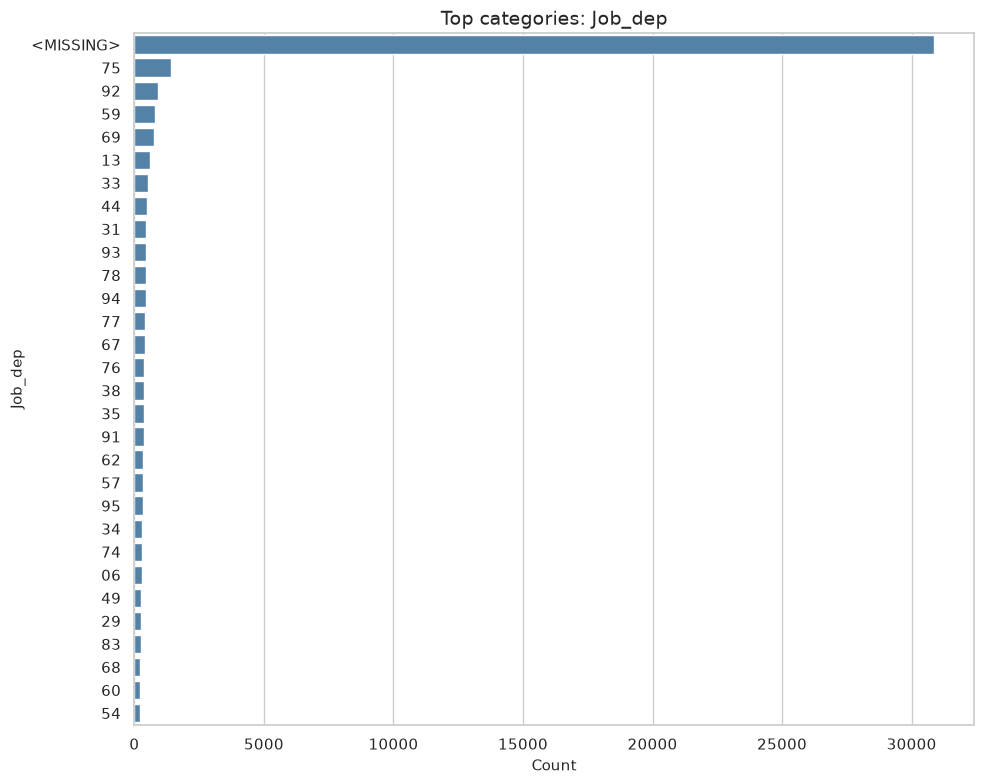

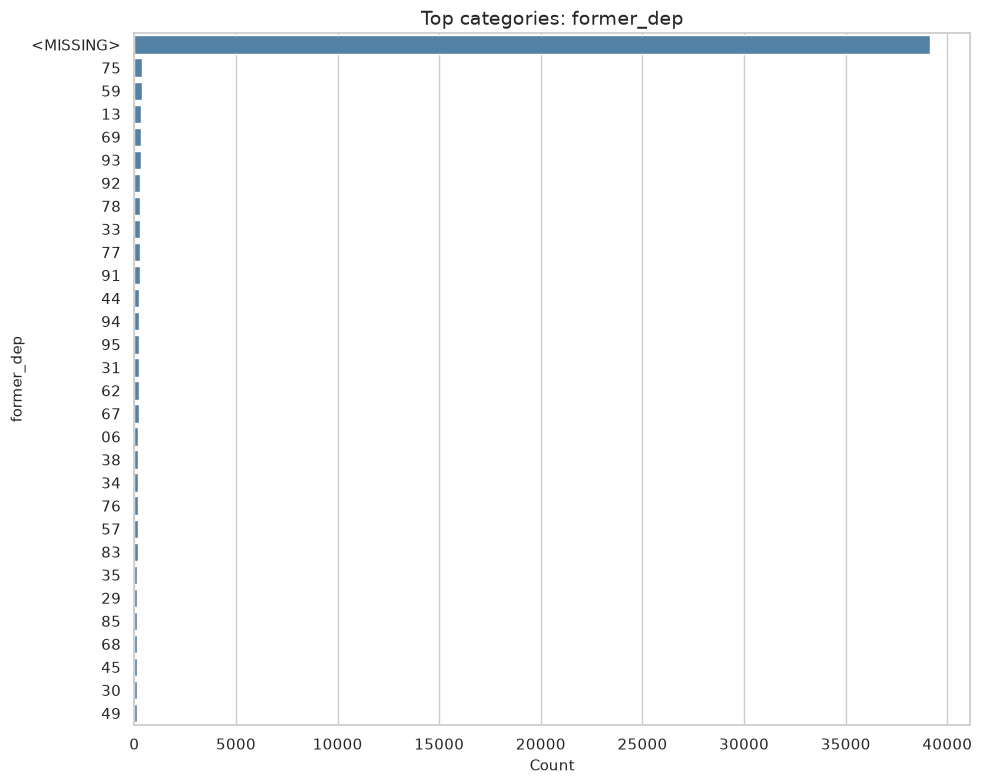

In [130]:
#department analysis
# %%
for col in ["dep", "Reg", "Job_dep", "former_dep"]:

    if col not in learn_features.columns:
        continue

    counts = (
        learn_features[col]
        .fillna("<MISSING>")
        .value_counts()
        .head(30)
    )

    plt.figure(figsize=(10, 8))

    sns.barplot(
        x=counts.values,
        y=counts.index,
        color="steelblue"
    )

    plt.title(
        f"Top categories: {col}"
    )

    plt.xlabel("Count")
    plt.ylabel(col)

    plt.tight_layout()
    plt.show()


In [131]:
#learn vs test missingness
# %%
common_columns = sorted(
    set(learn_features.columns)
    &
    set(test_features.columns)
)

distribution_comparison = []

for col in common_columns:

    distribution_comparison.append({
        "column": col,
        "learn_missing_%": (
            learn_features[col].isna().mean() * 100
        ),
        "test_missing_%": (
            test_features[col].isna().mean() * 100
        ),
        "missing_difference_pp": (
            learn_features[col].isna().mean()
            -
            test_features[col].isna().mean()
        ) * 100,
        "learn_unique": learn_features[col].nunique(
            dropna=True
        ),
        "test_unique": test_features[col].nunique(
            dropna=True
        ),
    })

distribution_comparison = pd.DataFrame(
    distribution_comparison
)

distribution_comparison[
    "abs_missing_difference_pp"
] = distribution_comparison[
    "missing_difference_pp"
].abs()

display(
    distribution_comparison
    .sort_values(
        "abs_missing_difference_pp",
        ascending=False
    )
    .head(30)
)


,column,learn_missing_%,test_missing_%,missing_difference_pp,learn_unique,test_unique,abs_missing_difference_pp
51,retirement_age,73.530352,73.282046,0.248306,26,31,0.248306
9,FORMER_EMP_CONTRACT,73.530352,73.282046,0.248306,7,7,0.248306
10,Former_job_42,73.530352,73.282046,0.248306,31,31,0.248306
36,club_federation,87.303681,87.149565,0.154115,96,96,0.154115
35,club_category,87.303681,87.149565,0.154115,5,5,0.154115
8,Employee_count_former_job,78.919394,78.783095,0.136299,7,7,0.136299
3,COMPANY_CATEGORY_former_job,79.055269,78.934959,0.120311,9,9,0.120311
39,former_dep,78.248012,78.141672,0.106339,96,96,0.106339
21,Job_dep_former_job,78.214043,78.111699,0.102344,96,96,0.102344
54,type_of_contract_former_job,77.532670,77.444300,0.088370,5,5,0.088370


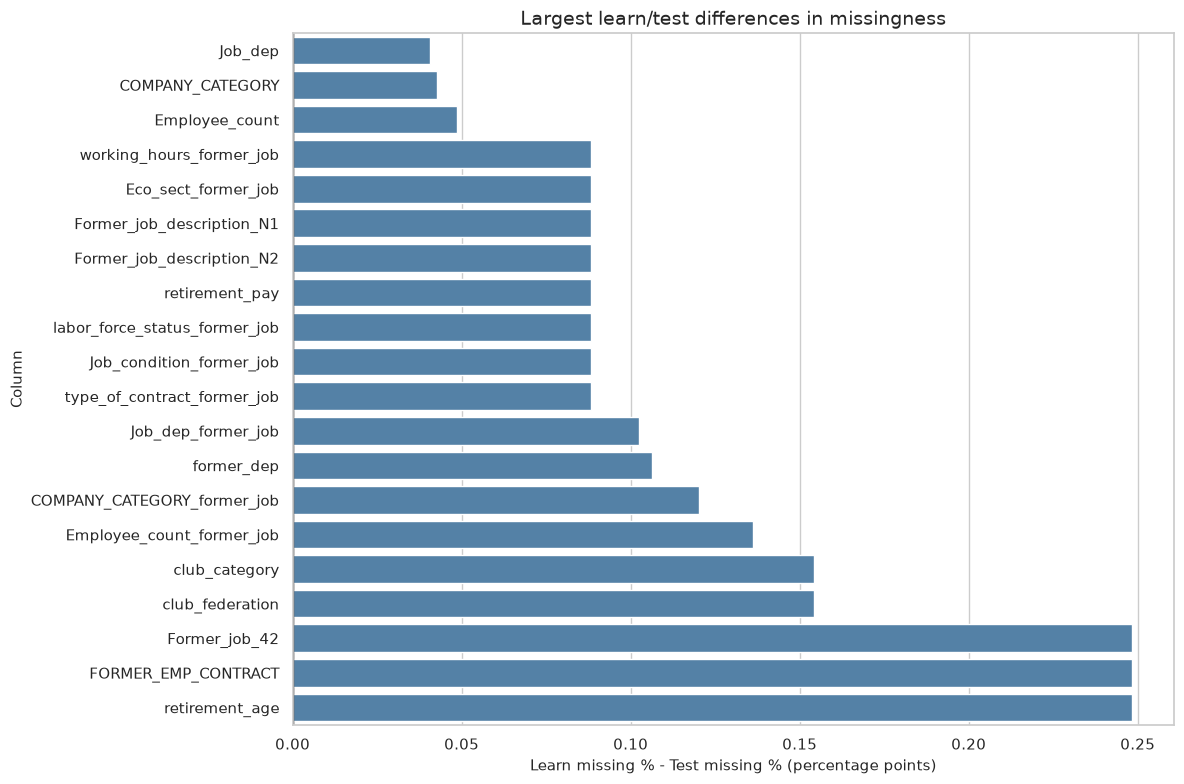

In [132]:
#visualize learn/test missingness differences
# %%
top_shift = (
    distribution_comparison
    .sort_values(
        "abs_missing_difference_pp",
        ascending=False
    )
    .head(20)
)

plt.figure(figsize=(12, 8))

plot_data = top_shift.copy()

plot_data = plot_data.sort_values(
    "missing_difference_pp"
)

sns.barplot(
    data=plot_data,
    x="missing_difference_pp",
    y="column",
    color="steelblue"
)

plt.axvline(
    0,
    color="black",
    linewidth=1
)

plt.title(
    "Largest learn/test differences in missingness"
)

plt.xlabel(
    "Learn missing % - Test missing % (percentage points)"
)

plt.ylabel("Column")

plt.tight_layout()
plt.show()


In [133]:
#Numeric train and test comparison
# %%
common_numeric = list(
    set(
        learn_features.select_dtypes(
            include=np.number
        ).columns
    )
    &
    set(
        test_features.select_dtypes(
            include=np.number
        ).columns
    )
)

numeric_comparison = []

for col in common_numeric:

    numeric_comparison.append({
        "column": col,

        "learn_mean": learn_features[col].mean(),
        "test_mean": test_features[col].mean(),

        "learn_median": learn_features[col].median(),
        "test_median": test_features[col].median(),

        "learn_std": learn_features[col].std(),
        "test_std": test_features[col].std(),

        "learn_missing_%": (
            learn_features[col].isna().mean() * 100
        ),

        "test_missing_%": (
            test_features[col].isna().mean() * 100
        ),
    })

numeric_comparison = pd.DataFrame(
    numeric_comparison
)

numeric_comparison["mean_difference"] = (
    numeric_comparison["learn_mean"]
    -
    numeric_comparison["test_mean"]
)

display(numeric_comparison)


,column,learn_mean,test_mean,learn_median,test_median,learn_std,test_std,learn_missing_%,test_missing_%,mean_difference
0,distance_to_paris_km,3.144378e+02,3.142112e+02,3.220954e+02,3.213053e+02,215.049740,215.127224,0.000000,0.000000,0.226592
1,working_hours_former_job,1.344680e+03,1.349774e+03,1.520000e+03,1.520000e+03,600.968524,601.485900,77.558646,77.470277,-5.094020
2,retirement_pay,1.849207e+04,1.887024e+04,1.690000e+04,1.694250e+04,7922.032987,11779.168592,77.532670,77.444300,-378.160499
3,log_inhabitants,9.200226e+00,9.173127e+00,9.212139e+00,9.181838e+00,1.914300,1.912120,0.000000,0.000000,0.027099
4,club_category,2.064212e+00,2.060799e+00,1.000000e+00,1.000000e+00,1.578314,1.551362,87.303681,87.149565,0.003412
5,retirement_age,6.036099e+01,6.031830e+01,6.000000e+01,6.000000e+01,2.812149,2.879288,73.530352,73.282046,0.042687
6,INHABITANTS,4.217942e+04,4.134650e+04,1.001700e+04,9.718000e+03,75478.017595,74720.703237,0.000000,0.000000,832.925798
7,LAT,4.705031e+01,4.704618e+01,4.766097e+01,4.765975e+01,2.260313,2.267031,0.000000,0.000000,0.004135
8,long,2.641016e+00,2.648546e+00,2.441625e+00,2.448162e+00,2.713959,2.690940,0.000000,0.000000,-0.007529
9,Age_2020,4.974342e+01,4.966970e+01,4.900000e+01,4.900000e+01,20.704045,20.616884,0.000000,0.000000,0.073719


In [134]:
#Statistical learn and test comparison
# %%
ks_results = []

for col in common_numeric:

    learn_values = (
        learn_features[col]
        .dropna()
    )

    test_values = (
        test_features[col]
        .dropna()
    )

    if len(learn_values) < 2 or len(test_values) < 2:
        continue

    statistic, p_value = stats.ks_2samp(
        learn_values,
        test_values
    )

    ks_results.append({
        "column": col,
        "KS_statistic": statistic,
        "p_value": p_value,
    })

ks_results = (
    pd.DataFrame(ks_results)
    .sort_values(
        "KS_statistic",
        ascending=False
    )
)

display(ks_results.head(30))


,column,KS_statistic,p_value
2,retirement_pay,0.014010,0.216813
12,PAY,0.009721,0.321958
3,log_inhabitants,0.009463,0.022492
6,INHABITANTS,0.009463,0.022492
11,working_hours,0.009428,0.358484
1,working_hours_former_job,0.008598,0.796433
4,club_category,0.007263,0.995354
5,retirement_age,0.006909,0.906326
10,X,0.005531,0.426811
8,long,0.005212,0.503191


In [135]:
#Automatically find suspicious columns
# %%
print("Potentially problematic features")
print("=" * 60)

# High missingness
high_missing = learn_features.isna().mean()

print("\nHigh missingness (>50%):")

display(
    high_missing[
        high_missing > 0.50
    ]
    .sort_values(
        ascending=False
    )
    .to_frame("missing_fraction")
)

# Very high cardinality
cardinality = learn_features.nunique(
    dropna=True
)

print("\nVery high cardinality (>100):")

display(
    cardinality[
        cardinality > 100
    ]
    .sort_values(
        ascending=False
    )
    .to_frame("unique_values")
)


Potentially problematic features

High missingness (>50%):


,missing_fraction
club_federation,0.873037
club_category,0.873037
COMPANY_CATEGORY_former_job,0.790553
Employee_count_former_job,0.789194
former_dep,0.782480
Job_dep_former_job,0.782140
working_hours_former_job,0.775586
Eco_sect_former_job,0.775327
retirement_pay,0.775327
Former_job_description_N1,0.775327



Very high cardinality (>100):


,unique_values
Pkey,50046
PAY,15534
INSEE_CODE,13514
X,13514
Y,13514
LAT,13514
long,13514
distance_to_paris_km,13514
Nom de la commune,13165
retirement_pay,8051


In [136]:
#duplicate uniqueness checks after all the pipeline
# %%
print("Final dataset checks")
print("=" * 60)

print(
    "Learn rows:",
    len(learn_features)
)

print(
    "Learn unique Pkeys:",
    learn_features[ID_COL].nunique()
)

print(
    "Learn duplicated Pkeys:",
    learn_features[ID_COL].duplicated().sum()
)

print()

print(
    "Test rows:",
    len(test_features)
)

print(
    "Test unique Pkeys:",
    test_features[ID_COL].nunique()
)

print(
    "Test duplicated Pkeys:",
    test_features[ID_COL].duplicated().sum()
)


Final dataset checks
Learn rows: 50046
Learn unique Pkeys: 50046
Learn duplicated Pkeys: 0

Test rows: 50045
Test unique Pkeys: 50045
Test duplicated Pkeys: 0


In [137]:
#Save features dataset
# %%
learn_output = OUTPUT_DIR / "learn_features.parquet"
test_output = OUTPUT_DIR / "test_features.parquet"

learn_features.to_parquet(
    learn_output,
    index=False
)

test_features.to_parquet(
    test_output,
    index=False
)

print("Saved:")
print(learn_output)
print(test_output)


Saved:
/home/jlopez/github/Dauphine/machine_learning/project/outputs/learn_features.parquet
/home/jlopez/github/Dauphine/machine_learning/project/outputs/test_features.parquet


In [138]:
#Save statistical analysis
# %%
statistics_dir = OUTPUT_DIR / "statistics"
statistics_dir.mkdir(
    parents=True,
    exist_ok=True
)

inventory_df.to_csv(
    statistics_dir / "dataset_inventory.csv",
    index=False
)

numeric_stats.to_csv(
    statistics_dir / "numeric_statistics.csv"
)

categorical_stats.to_csv(
    statistics_dir / "categorical_statistics.csv",
    index=False
)

missing.to_csv(
    statistics_dir / "missing_values.csv"
)

outliers.to_csv(
    statistics_dir / "outliers.csv",
    index=False
)

learn_merge_diagnostics.to_csv(
    statistics_dir / "merge_diagnostics.csv",
    index=False
)

distribution_comparison.to_csv(
    statistics_dir / "learn_test_comparison.csv",
    index=False
)

if len(ks_results):
    ks_results.to_csv(
        statistics_dir / "learn_test_ks_tests.csv",
        index=False
    )

print(
    f"Statistics saved to: {statistics_dir}"
)


Statistics saved to: /home/jlopez/github/Dauphine/machine_learning/project/outputs/statistics


In [139]:
#Final summary
# # %%
display(Markdown("# Analysis summary"))

print(f"Learn dataset: {learn_features.shape[0]:,} rows × {learn_features.shape[1]:,} columns")
print(f"Test dataset:  {test_features.shape[0]:,} rows × {test_features.shape[1]:,} columns")

print(
    f"\nOriginal person columns: {persons_learn.shape[1]:,}"
)

print(
    f"Engineered columns added: {len(engineered_columns):,}"
)

print(
    f"\nLearn duplicate Pkeys: "
    f"{learn_features[ID_COL].duplicated().sum():,}"
)

print(
    f"Test duplicate Pkeys: "
    f"{test_features[ID_COL].duplicated().sum():,}"
)

if TARGET_COL in learn_features.columns:

    print("\nTarget distribution:")
    display(
        learn_features[TARGET_COL]
        .value_counts(normalize=True)
        .mul(100)
        .round(2)
        .rename("percentage")
    )



# Analysis summary

Learn dataset: 50,046 rows × 58 columns
Test dataset:  50,045 rows × 57 columns

Original person columns: 10
Engineered columns added: 48

Learn duplicate Pkeys: 0
Test duplicate Pkeys: 0

Target distribution:


target
I    55.35
T    44.65
Name: percentage, dtype: float64